# Evento Evaluativo 4 — Equipo 10
## Detección de ofertas laborales fraudulentas y análisis de patrones textuales

**Asignatura:** Análisis de Datos · **Docente:** Daniel Alexis Nieto Mora · **Periodo:** 2026-2

**Integrantes (GitHub):** @dariomontoya0505, @Franyelica, @santiagopabon15 y Darwin (@Casper128).

**Dataset:** *Real or Fake Job Posting Prediction* (EMSCAD, Universidad del Egeo) — Kaggle.

---
### Contenido
1. Descripción del problema
2. Comprensión y exploración de los datos (EDA)
3. Preprocesamiento
4. Componente supervisado
5. Componente no supervisado
6. Visualización y reducción de dimensionalidad
7. Análisis comparativo supervisado vs. no supervisado
8. Conclusiones y recomendaciones

**Estado de revisión:** este notebook conserva resultados de la ejecución original. Se corrigió la selección del modelo para usar validación, y se añadieron precisiones metodológicas. Las celdas modificadas requieren una ejecución completa con el CSV antes de presentar las cifras como resultados de esta versión. Consulta `docs/revision_rubrica.md`.

**Relación con el curso:** estadística y correlaciones (semana 4), preparación y reducción de dimensiones (semana 5), comunicación de hallazgos (semanas 7–8), regresión logística, SVM, K-Means y t-SNE (semanas 12–13). TF-IDF y Ward complementan estos temas para cumplir el reto textual.

## 1. Descripción del problema

Las plataformas de empleo pueden usarse para publicar **ofertas falsas** cuyo fin es robar datos personales,
cobrar "tarifas de contratación" o atraer a las personas a esquemas de estafa. Revisar manualmente cada
publicación es costoso, por lo que interesa un sistema que **priorice** las ofertas sospechosas para revisión.

El conjunto contiene ~18 mil publicaciones con campos de texto libre (perfil de la empresa, descripción,
requisitos, beneficios), campos categóricos (tipo de empleo, experiencia, educación, industria, función,
ubicación) e indicadores binarios (logo, preguntas de filtro, teletrabajo). La etiqueta `fraudulent` indica si la
oferta es falsa.

**Componente supervisado:** clasificar ofertas como legítimas (0) o fraudulentas (1), comparando la capacidad
predictiva de **(a) variables estructuradas**, **(b) texto** y **(c) la combinación de ambas**.

**Componente no supervisado:** con TF-IDF + agrupamiento descubrir temáticas en las publicaciones *sin usar la
etiqueta*, y después verificar si algunos grupos concentran fraude.

**Preguntas que buscamos responder**
1. ¿Qué características (estructuradas y textuales) distinguen a una oferta fraudulenta?
2. ¿El texto aporta más que las variables estructuradas? ¿Su combinación mejora el desempeño?
3. ¿Cómo manejar un desbalance de clases fuerte sin que la métrica nos engañe?
4. ¿Existen temáticas (grupos) de publicaciones donde el fraude se concentra, descubiertas sin etiquetas?
5. ¿Qué modelo recomendaríamos para un sistema real de moderación y con qué limitaciones?

In [ ]:
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, Normalizer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve, classification_report,
                             silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

from IPython.display import display
# Conservamos advertencias de convergencia para revisar el entrenamiento.
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").exists() and (PROJECT_DIR / "evaluacion 4").exists():
    PROJECT_DIR = PROJECT_DIR / "evaluacion 4"
DATA_PATH = PROJECT_DIR / "data" / "fake_job_postings.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Descarga fake_job_postings.csv de Kaggle y colócalo en evaluacion 4/data/.")
FIG_DIR = PROJECT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

## 2. Comprensión y exploración de los datos
### 2.1 Estructura general

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dimensiones:", df.shape)
df.head(3)

Dimensiones: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


In [3]:
info = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "pct_faltantes": (df.isna().mean() * 100).round(1),
})
info

,tipo,n_unicos,pct_faltantes
job_id,int64,17880,0.0
title,str,11231,0.0
location,str,3105,1.9
department,str,1337,64.6
salary_range,str,874,84.0
company_profile,str,1709,18.5
description,str,14801,0.0
requirements,str,11967,15.1
benefits,str,6204,40.3
telecommuting,int64,2,0.0


**Diccionario de variables**

| Grupo | Variables | Comentario |
|---|---|---|
| Identificador | `job_id` | No predictivo; se descarta. |
| Texto libre | `title`, `company_profile`, `description`, `requirements`, `benefits` | Fuente principal de señal textual. |
| Categóricas | `location`, `department`, `salary_range`, `employment_type`, `required_experience`, `required_education`, `industry`, `function` | Varias con alta cardinalidad y muchos faltantes. |
| Binarias | `telecommuting`, `has_company_logo`, `has_questions` | Indicadores de la publicación. |
| Objetivo | `fraudulent` | 1 = oferta falsa. |

In [4]:
TEXT_COLS = ["title", "company_profile", "description", "requirements", "benefits"]
n_dup = df.drop(columns="job_id").duplicated().sum()
n_dup_txt = df.duplicated(subset=TEXT_COLS).sum()
print(f"Duplicados exactos (todas las columnas salvo job_id): {n_dup}")
print(f"Ofertas cuyo texto completo repite el de otra oferta: {n_dup_txt} "
      f"({df[df.duplicated(subset=TEXT_COLS)]['fraudulent'].sum()} de ellas fraudulentas)")
df = df.drop_duplicates(subset=[c for c in df.columns if c != "job_id"]).reset_index(drop=True)
print("Dimensiones tras eliminar duplicados exactos:", df.shape)

Duplicados exactos (todas las columnas salvo job_id): 281
Ofertas cuyo texto completo repite el de otra oferta: 1814 (148 de ellas fraudulentas)
Dimensiones tras eliminar duplicados exactos: (17599, 18)


**Duplicados:** 281 registros son copias exactas y se eliminan. Además, ~1 800 ofertas repiten el texto completo de
otra (la misma publicación replicada en varias ciudades). Esas no se eliminan —son publicaciones distintas—, pero se
tratan como **grupos** en la partición entrenamiento/prueba para que el modelo no "memorice" un texto y luego lo
encuentre en prueba (fuga de información que inflaría las métricas).

fraudulent
0    16743
1      856
Name: count, dtype: int64 
Proporción de fraude: 4.86%


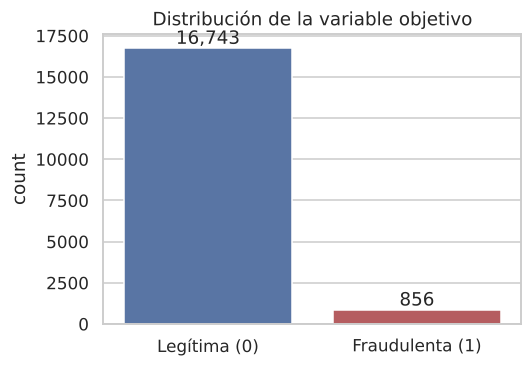

In [5]:
target_counts = df["fraudulent"].value_counts().sort_index()
print(target_counts, "\nProporción de fraude: {:.2%}".format(df["fraudulent"].mean()))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x="fraudulent", data=df, ax=ax, palette=["#4C72B0", "#C44E52"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_xticklabels(["Legítima (0)", "Fraudulenta (1)"]); ax.set_xlabel(""); ax.set_title("Distribución de la variable objetivo")
savefig("01_target")

**Hallazgo:** el problema está **fuertemente desbalanceado** (~5 % de fraude). Un clasificador que siempre
responda "legítima" tendría ~95 % de *accuracy*, por lo que esa métrica es engañosa. Usaremos **Precision, Recall,
F1 de la clase positiva, matriz de confusión y PR-AUC** (la ROC-AUC se reporta como complemento, pero con
desbalance tiende a ser optimista).

### 2.2 Valores faltantes y su relación con el fraude

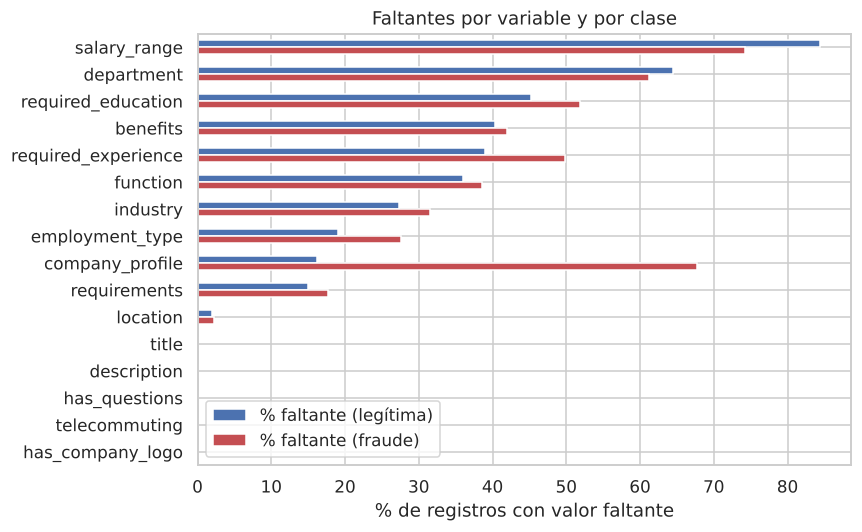

,% faltante (legítima),% faltante (fraude)
salary_range,84.4,74.2
department,64.5,61.2
required_education,45.2,51.9
benefits,40.3,41.9
required_experience,39.0,49.9
function,36.0,38.6
industry,27.3,31.5
employment_type,19.1,27.6
company_profile,16.1,67.8
requirements,14.9,17.6


In [6]:
miss = df.drop(columns=["job_id", "fraudulent"]).isna()
miss_by_class = miss.groupby(df["fraudulent"]).mean().T * 100
miss_by_class.columns = ["% faltante (legítima)", "% faltante (fraude)"]
miss_by_class = miss_by_class.sort_values("% faltante (legítima)", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
miss_by_class.plot.barh(ax=ax, color=["#4C72B0", "#C44E52"])
ax.invert_yaxis(); ax.set_xlabel("% de registros con valor faltante")
ax.set_title("Faltantes por variable y por clase")
savefig("02_missing_by_class")
miss_by_class.round(1)

**Hallazgo:** los faltantes **no son aleatorios**: en varias columnas (p. ej. `company_profile`) la ausencia es
mucho más frecuente en ofertas fraudulentas. Por eso no basta con imputar: **la ausencia misma es información** y
se codificará como indicador binario (`missing_*`) y como categoría explícita `"Missing"` en las categóricas.

### 2.3 Variables binarias y categóricas

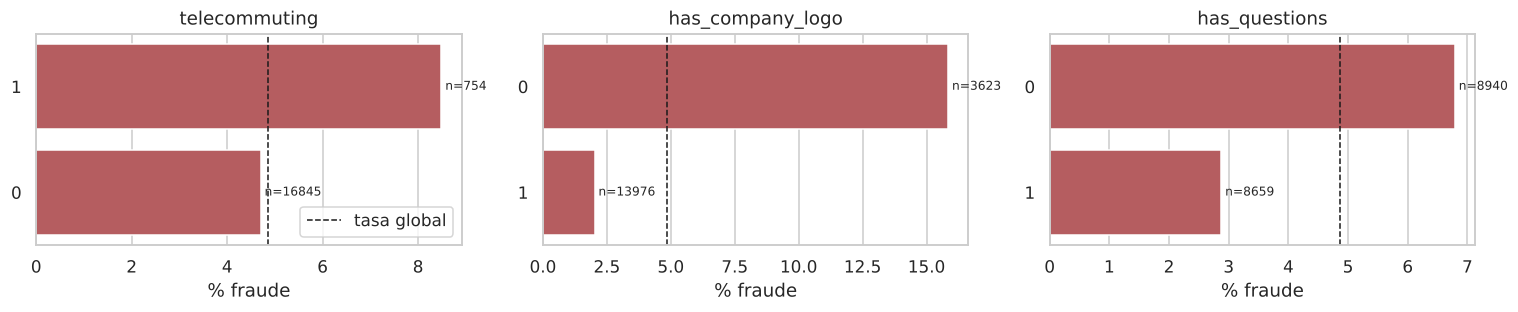

In [7]:
def fraud_rate_plot(col, ax, top=None, min_count=1):
    g = df.groupby(df[col].fillna("Missing"))["fraudulent"].agg(["mean", "count"])
    g = g[g["count"] >= min_count].sort_values("mean", ascending=False)
    if top: g = g.head(top)
    sns.barplot(x=g["mean"] * 100, y=g.index.astype(str), ax=ax, color="#C44E52")
    ax.axvline(df["fraudulent"].mean() * 100, ls="--", c="k", lw=1, label="tasa global")
    ax.set_xlabel("% fraude"); ax.set_ylabel(""); ax.set_title(col)
    for i, (m, c) in enumerate(zip(g["mean"], g["count"])):
        ax.text(m * 100, i, f" n={c}", va="center", fontsize=8)
    return g

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, c in zip(axes, ["telecommuting", "has_company_logo", "has_questions"]):
    fraud_rate_plot(c, ax)
axes[0].legend()
savefig("03_binarias")

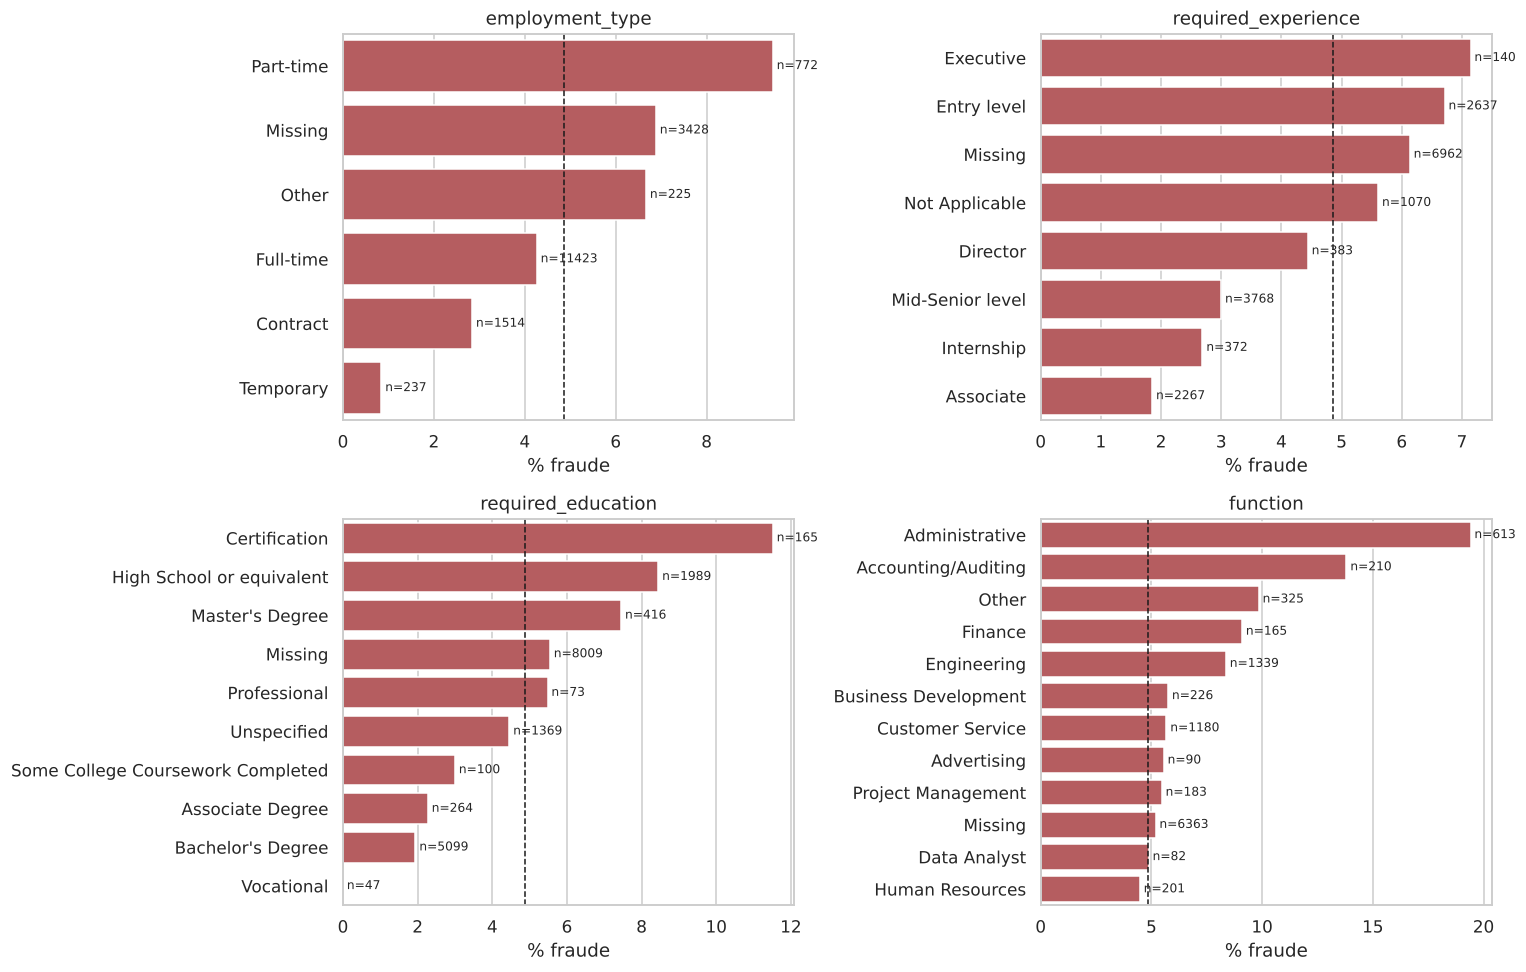

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, c in zip(axes.ravel(), ["employment_type", "required_experience", "required_education", "function"]):
    fraud_rate_plot(c, ax, top=12, min_count=30)
savefig("04_categoricas")

### 2.4 Ubicación, salario e industria (alta cardinalidad)

Cardinalidad:
 location        3105
country           91
industry         131
function          37
department      1337
salary_range     874
dtype: int64


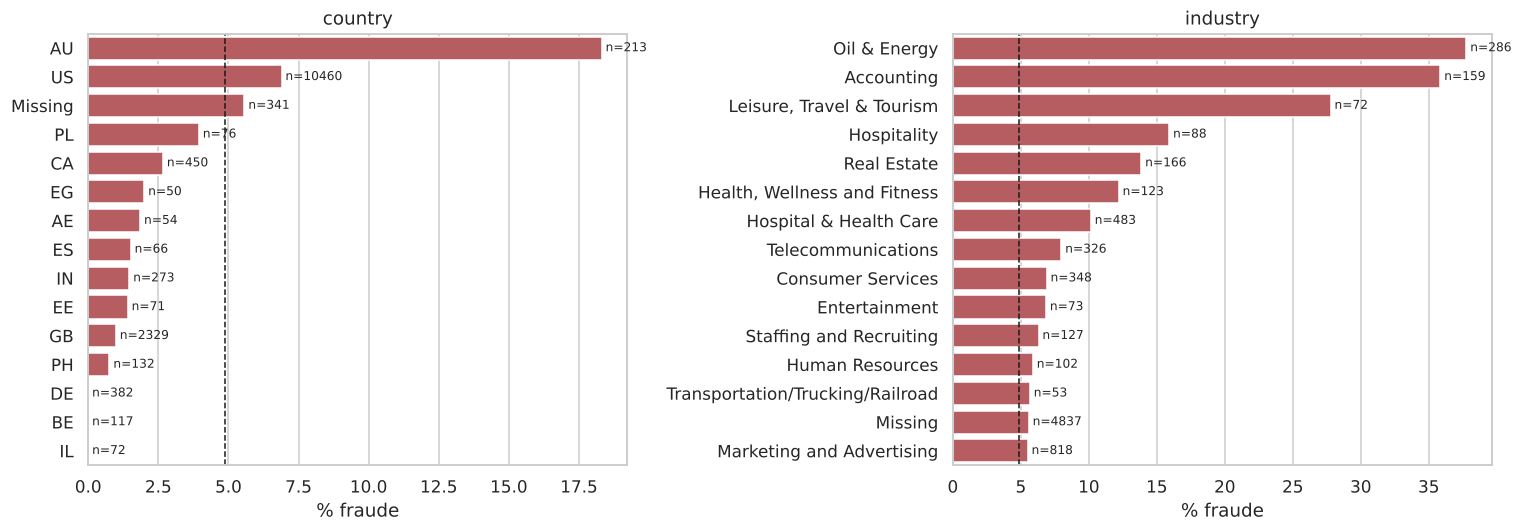

has_salary
0    0.042987
1    0.078175
Name: tasa de fraude, dtype: float64


In [9]:
df["country"] = df["location"].fillna("").str.split(",").str[0].str.strip().replace("", "Missing")
card = df[["location", "country", "industry", "function", "department", "salary_range"]].nunique()
print("Cardinalidad:\n", card)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fraud_rate_plot("country", axes[0], top=15, min_count=50)
fraud_rate_plot("industry", axes[1], top=15, min_count=50)
savefig("05_pais_industria")

df["has_salary"] = df["salary_range"].notna().astype(int)
print(df.groupby("has_salary")["fraudulent"].mean().rename("tasa de fraude"))

**Hallazgos:**
* `location`, `industry`, `department` y `salary_range` tienen **alta cardinalidad**. Para no crear miles de
  columnas dispersas, de `location` se extrae solo el **país**, y en el *One-Hot Encoding* las categorías con
  menos de 20 registros se agrupan como "infrecuentes".
* `department` y `salary_range` tienen >60 % de faltantes y valores muy heterogéneos: se conservan solo como
  indicadores (tiene / no tiene).
* Algunas industrias (p. ej. petróleo y energía) y algunos países concentran tasas de fraude muy superiores a la
  media; ver las cifras en las gráficas.

### 2.5 Características del texto

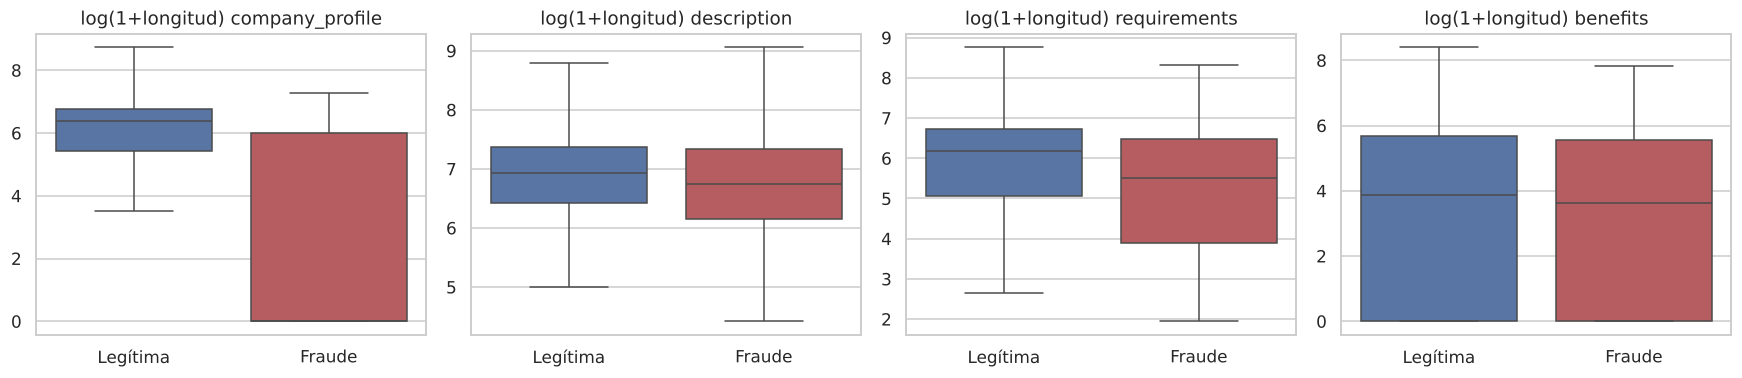

,n_url,n_email,n_phone
fraudulent,,,
0,0.614,0.073,0.040
1,0.500,0.258,0.103


In [10]:
TEXT_COLS = ["title", "company_profile", "description", "requirements", "benefits"]
for c in TEXT_COLS:
    df[f"len_{c}"] = df[c].fillna("").str.len()

raw_all = df[TEXT_COLS].fillna("").agg(" ".join, axis=1)
df["n_url"] = raw_all.str.count(r"#URL_")
df["n_email"] = raw_all.str.count(r"#EMAIL_")
df["n_phone"] = raw_all.str.count(r"#PHONE_")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, c in zip(axes, ["company_profile", "description", "requirements", "benefits"]):
    sns.boxplot(x="fraudulent", y=np.log1p(df[f"len_{c}"]), data=df, ax=ax, palette=["#4C72B0", "#C44E52"], showfliers=False)
    ax.set_title(f"log(1+longitud) {c}"); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticklabels(["Legítima", "Fraude"])
savefig("06_longitud_texto")

df.groupby("fraudulent")[["n_url", "n_email", "n_phone"]].mean().round(3)

El dataset ya viene **anonimizado**: URLs, correos y teléfonos aparecen como tokens `#URL_...#`, `#EMAIL_...#`,
`#PHONE_...#`. Contarlos permite capturar si la oferta invita a contactar por fuera de la plataforma.

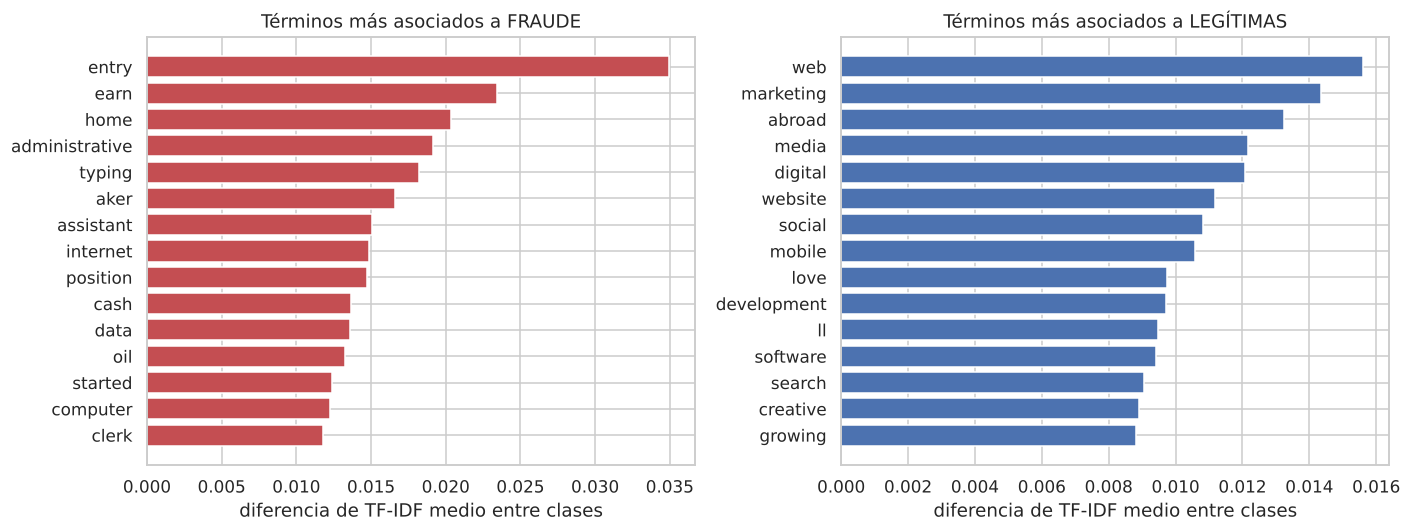

In [11]:
def quick_clean(s):
    s = re.sub(r"#(URL|EMAIL|PHONE)_[^#]*#", " ", s)
    s = re.sub(r"([a-z])([A-Z])", r"\1 \2", s)
    s = re.sub(r"[^a-zA-Z ]", " ", s).lower()
    return s

def top_terms_by_class(texts, y, n=15):
    vec = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5)
    X = vec.fit_transform(texts)
    terms = np.array(vec.get_feature_names_out())
    m1 = np.asarray(X[y == 1].mean(axis=0)).ravel()
    m0 = np.asarray(X[y == 0].mean(axis=0)).ravel()
    diff = m1 - m0
    return terms[np.argsort(diff)[::-1][:n]], diff[np.argsort(diff)[::-1][:n]], terms[np.argsort(diff)[:n]], diff[np.argsort(diff)[:n]]

tf, vf, tl, vl = top_terms_by_class(raw_all.map(quick_clean), df["fraudulent"].values)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(tf[::-1], vf[::-1], color="#C44E52"); axes[0].set_title("Términos más asociados a FRAUDE")
axes[1].barh(tl[::-1], -vl[::-1], color="#4C72B0"); axes[1].set_title("Términos más asociados a LEGÍTIMAS")
for a in axes: a.set_xlabel("diferencia de TF-IDF medio entre clases")
savefig("07_terminos_por_clase")

*(Este análisis de términos es exploratorio, sobre todo el dataset; en el modelado el TF-IDF se ajusta
**solo con entrenamiento**.)*

### 2.6 Relaciones entre variables numéricas

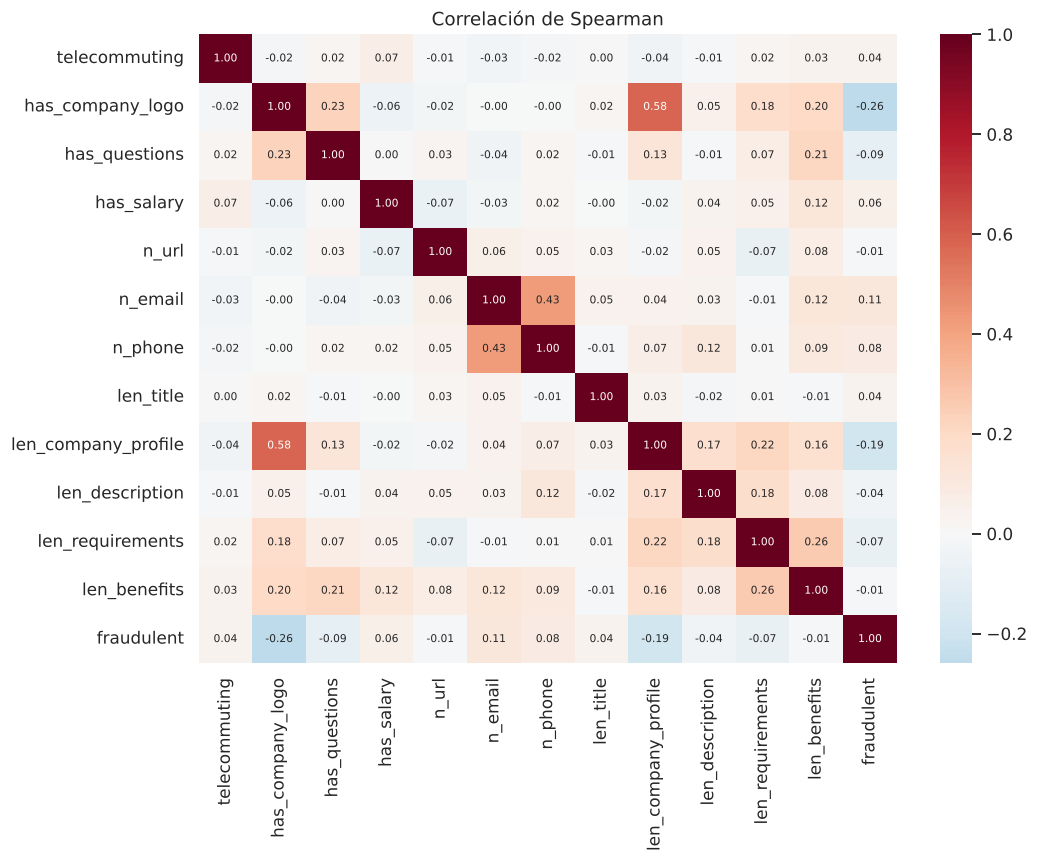

In [12]:
num_eda = ["telecommuting", "has_company_logo", "has_questions", "has_salary", "n_url", "n_email", "n_phone"] + \
          [f"len_{c}" for c in TEXT_COLS] + ["fraudulent"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_eda].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlación de Spearman")
savefig("08_correlaciones")

### 2.7 Resumen del EDA
* **Desbalance severo** (~5 % fraude) → métricas centradas en la clase positiva, estratificación y estrategias de
  desbalance.
* **Faltantes informativos**: perfil de empresa vacío, sin logo y sin preguntas de filtro se asocian con fraude.
* **Alta cardinalidad** en ubicación, industria y departamento → extracción de país + agrupación de categorías raras.
* **Texto**: las ofertas fraudulentas tienden a ser más cortas en el perfil de la empresa y usan vocabulario
  distinto (ver figura 07). Ninguna variable aislada separa las clases: se necesita combinar señales.

## 3. Preprocesamiento

**Decisiones y justificación**

| Paso | Qué se hace | Por qué |
|---|---|---|
| Limpieza de texto | Separar palabras pegadas (`workCompany`→`work Company`), quitar HTML/entidades, reemplazar `#URL_…#` por `urltoken` (igual email/teléfono), minúsculas, dejar solo letras. | El texto viene sin saltos de línea y con tokens anonimizados. |
| Texto combinado | `title + company_profile + description + requirements + benefits` | Una sola representación TF-IDF por oferta. |
| TF-IDF | unigramas + bigramas, `min_df=3`, `max_df=0.9`, `sublinear_tf`, stop words en inglés | Pondera términos distintivos y reduce el peso de palabras comunes. |
| Faltantes categóricos | Categoría explícita `"Missing"` | La ausencia es informativa (sección 2.2). |
| Alta cardinalidad | País desde `location`; One-Hot con `min_frequency=20` | Evita miles de columnas raras y el sobreajuste. |
| Numéricas | `log1p` de longitudes y conteos + `StandardScaler` | Distribuciones muy asimétricas; los modelos lineales lo necesitan. |
| Descartadas | `job_id`, `location` cruda, `department`, `salary_range` crudos | ID sin significado; cardinalidad extrema → se usan como indicadores. |
| Duplicados | Se eliminan los duplicados exactos (281) y las ofertas con **texto idéntico** se tratan como un grupo. | Evita que la misma publicación quede en entrenamiento y en prueba. |
| **Anti-fuga** | Partición 80/20 **estratificada por clase y agrupada por texto** (`StratifiedGroupKFold`) **antes** de ajustar cualquier transformación; la validación cruzada también es agrupada; todo vive dentro de `Pipeline` y se reajusta en cada pliegue. | El TF-IDF (vocabulario e IDF), escaladores y codificadores aprenden de los datos; los textos repetidos inflarían las métricas. |

In [13]:
def clean_text(s: str) -> str:
    s = re.sub(r"#URL_[^#]*#", " urltoken ", s)
    s = re.sub(r"#EMAIL_[^#]*#", " emailtoken ", s)
    s = re.sub(r"#PHONE_[^#]*#", " phonetoken ", s)
    s = re.sub(r"&\w+;", " ", s)
    s = re.sub(r"<[^>]+>", " ", s)
    s = re.sub(r"([a-z])([A-Z])", r"\1 \2", s)
    s = s.lower()
    s = re.sub(r"[^a-z\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df["text"] = df[TEXT_COLS].fillna("").agg(" ".join, axis=1).map(clean_text)

CAT_COLS = ["employment_type", "required_experience", "required_education", "function", "industry", "country"]
for c in CAT_COLS:
    df[c] = df[c].fillna("Missing").astype(str)

MISS_SRC = ["company_profile", "description", "requirements", "benefits", "department", "salary_range"]
for c in MISS_SRC:
    df[f"missing_{c}"] = df[c].isna().astype(int)

LOG_COLS = [f"len_{c}" for c in TEXT_COLS] + ["n_url", "n_email", "n_phone"]
for c in LOG_COLS:
    df[f"log_{c}"] = np.log1p(df[c])

NUM_COLS = ["telecommuting", "has_company_logo", "has_questions", "has_salary"] + \
           [f"missing_{c}" for c in MISS_SRC] + [f"log_{c}" for c in LOG_COLS]

print("Ejemplo de texto limpio:\n", df["text"].iloc[0][:400])

Ejemplo de texto limpio:
 marketing intern we re food and we ve created a groundbreaking and award winning cooking site we support connect and celebrate home cooks and give them everything they need in one place we have a top editorial business and engineering team we re focused on using technology to find new and better ways to connect people around their specific food interests and to offer them superb highly curated inf


In [14]:
FEATURES = ["text"] + CAT_COLS + NUM_COLS
X = df[FEATURES]
y = df["fraudulent"].values
# Grupo = ofertas con texto idéntico (misma publicación replicada en varias ciudades).
# Todas las copias van al mismo lado de la partición → no hay fuga por duplicados.
groups = pd.util.hash_pandas_object(df[TEXT_COLS].fillna(""), index=False).values
print("Grupos de texto únicos:", len(np.unique(groups)), "de", len(df), "ofertas")
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, te_idx = next(sgkf.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[tr_idx], X.iloc[te_idx], y[tr_idx], y[te_idx]
g_train = groups[tr_idx]
assert not set(groups[tr_idx]) & set(groups[te_idx])
print(f"Train: {X_train.shape} ({y_train.mean():.2%} fraude) | Test: {X_test.shape} ({y_test.mean():.2%} fraude)")

Grupos de texto únicos: 16066 de 17599 ofertas


Train: (14079, 25) (4.87% fraude) | Test: (3520, 25) (4.86% fraude)


In [15]:
def make_tfidf(max_features=50000):
    return TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.9,
                           sublinear_tf=True, max_features=max_features)

def make_ohe(dense=False):
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=not dense)

def prep_structured(dense=False):
    return ColumnTransformer([
        ("cat", make_ohe(dense), CAT_COLS),
        ("num", StandardScaler(), NUM_COLS),
    ])

def prep_text():
    return ColumnTransformer([("txt", make_tfidf(), "text")])

def prep_combined():
    return ColumnTransformer([
        ("txt", make_tfidf(), "text"),
        ("cat", make_ohe(), CAT_COLS),
        ("num", StandardScaler(), NUM_COLS),
    ])

## 4. Componente supervisado

### 4.1 Algoritmos seleccionados y justificación

| Algoritmo | Por qué es apropiado | Supuestos | Ventajas | Limitaciones |
|---|---|---|---|---|
| **Regresión Logística** (L2, `class_weight="balanced"`) | Referente clásico para texto TF-IDF de alta dimensión y disperso. | Relación lineal entre variables y log-odds; observaciones independientes. | Rápida, entrega probabilidades, coeficientes interpretables (qué palabras empujan a fraude). | No captura interacciones no lineales; sensible a colinealidad (mitigada por la regularización). |
| **SVM lineal** (`LinearSVC`) | Maximiza el margen; muy eficaz en clasificación de texto con muchas variables. | Clases (aprox.) separables linealmente en el espacio TF-IDF. | Robusta en alta dimensión, buen desempeño con texto. | No da probabilidades calibradas (usamos `decision_function`); menos interpretable que la LR. |
| **Random Forest** (solo variables estructuradas) | Captura interacciones no lineales entre indicadores (p. ej. sin logo **y** sin perfil). | Ninguno fuerte sobre la distribución. | Robusto a escalas, importancia de variables. | Poco eficiente con TF-IDF disperso de 50k columnas; por eso se usa en el enfoque estructurado. |
| **Histogram Gradient Boosting** (estructurado) | *Boosting* potente para datos tabulares. | — | Suele superar a RF en tabulares; maneja desbalance con pesos. | Más hiperparámetros; riesgo de sobreajuste si no se regula. |

**Estrategias de desbalance comparadas:** (i) sin tratamiento, (ii) **ponderación de clases**
(`class_weight="balanced"`), (iii) **submuestreo aleatorio** de la clase mayoritaria *dentro* del pipeline
(solo en los pliegues de entrenamiento), y (iv) **ajuste del umbral de decisión** con predicciones *out-of-fold*.
Se descarta SMOTE porque generar ejemplos sintéticos interpolando vectores TF-IDF dispersos produce documentos
artificiales sin sentido.

**Protocolo:** validación cruzada estratificada **y agrupada por texto** de 5 pliegues **sobre el entrenamiento** para comparar y ajustar;
el conjunto de prueba se usa **una sola vez** al final.

In [16]:
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1", "precision": "precision", "recall": "recall"}
cv_results = {}

def cv_eval(name, model, Xtr=X_train, ytr=y_train, cv=CV):
    t = time.time()
    r = cross_validate(model, Xtr, ytr, groups=g_train, cv=cv, scoring=SCORING, n_jobs=1)
    cv_results[name] = {k: r[f"test_{k}"].mean() for k in SCORING} | \
                       {f"{k}_std": r[f"test_{k}"].std() for k in ["pr_auc", "f1"]}
    print(f"{name:<45} PR-AUC={cv_results[name]['pr_auc']:.3f}±{cv_results[name]['pr_auc_std']:.3f} "
          f"F1={cv_results[name]['f1']:.3f} P={cv_results[name]['precision']:.3f} R={cv_results[name]['recall']:.3f} "
          f"({time.time()-t:.0f}s)")

### 4.2 Enfoque A — solo variables estructuradas

In [17]:
cv_eval("A | LogReg balanced (estructurado)",
        Pipeline([("prep", prep_structured()), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]))
cv_eval("A | RandomForest balanced (estructurado)",
        Pipeline([("prep", prep_structured()), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]))
cv_eval("A | HistGradientBoosting balanced (estructurado)",
        Pipeline([("prep", prep_structured(dense=True)), ("clf", HistGradientBoostingClassifier(
                  class_weight="balanced", learning_rate=0.08, max_iter=300, random_state=SEED))]))

A | LogReg balanced (estructurado)            PR-AUC=0.463±0.065 F1=0.392 P=0.254 R=0.854 (3s)


A | RandomForest balanced (estructurado)      PR-AUC=0.800±0.018 F1=0.707 P=0.699 R=0.718 (22s)


A | HistGradientBoosting balanced (estructurado) PR-AUC=0.794±0.012 F1=0.652 P=0.532 R=0.844 (8s)


### 4.3 Enfoque B — solo texto (TF-IDF)

In [18]:
cv_eval("B | LogReg balanced (texto)",
        Pipeline([("prep", prep_text()), ("clf", LogisticRegression(max_iter=3000, C=4, class_weight="balanced"))]))
cv_eval("B | LinearSVC balanced (texto)",
        Pipeline([("prep", prep_text()), ("clf", LinearSVC(C=0.3, class_weight="balanced"))]))

B | LogReg balanced (texto)                   PR-AUC=0.902±0.021 F1=0.834 P=0.846 R=0.823 (34s)


B | LinearSVC balanced (texto)                PR-AUC=0.910±0.019 F1=0.850 P=0.883 R=0.820 (37s)


### 4.4 Enfoque C — texto + estructuradas, y comparación de estrategias de desbalance

In [19]:
cv_eval("C | LogReg SIN tratamiento (combinado)",
        Pipeline([("prep", prep_combined()), ("clf", LogisticRegression(max_iter=3000, C=4))]))
cv_eval("C | LogReg balanced (combinado)",
        Pipeline([("prep", prep_combined()), ("clf", LogisticRegression(max_iter=3000, C=4, class_weight="balanced"))]))
cv_eval("C | LogReg + submuestreo (combinado)",
        ImbPipeline([("prep", prep_combined()), ("rus", RandomUnderSampler(random_state=SEED)),
                     ("clf", LogisticRegression(max_iter=3000, C=4))]))
cv_eval("C | LinearSVC SIN tratamiento (combinado)",
        Pipeline([("prep", prep_combined()), ("clf", LinearSVC(C=0.3))]))
cv_eval("C | LinearSVC balanced (combinado)",
        Pipeline([("prep", prep_combined()), ("clf", LinearSVC(C=0.3, class_weight="balanced"))]))

C | LogReg SIN tratamiento (combinado)        PR-AUC=0.878±0.032 F1=0.768 P=0.906 R=0.673 (39s)


C | LogReg balanced (combinado)               PR-AUC=0.891±0.031 F1=0.788 P=0.722 R=0.870 (42s)


C | LogReg + submuestreo (combinado)          PR-AUC=0.642±0.048 F1=0.482 P=0.326 R=0.930 (36s)


C | LinearSVC SIN tratamiento (combinado)     PR-AUC=0.906±0.027 F1=0.785 P=0.948 R=0.674 (41s)


C | LinearSVC balanced (combinado)            PR-AUC=0.909±0.027 F1=0.831 P=0.801 R=0.864 (46s)


In [20]:
res = pd.DataFrame(cv_results).T.sort_values("pr_auc", ascending=False)
res.round(3)

,pr_auc,roc_auc,f1,precision,recall,pr_auc_std,f1_std
B | LinearSVC balanced (texto),0.910,0.985,0.850,0.883,0.820,0.019,0.027
C | LinearSVC balanced (combinado),0.909,0.989,0.831,0.801,0.864,0.027,0.023
C | LinearSVC SIN tratamiento (combinado),0.906,0.987,0.785,0.948,0.674,0.027,0.061
B | LogReg balanced (texto),0.902,0.984,0.834,0.846,0.823,0.021,0.027
C | LogReg balanced (combinado),0.891,0.988,0.788,0.722,0.870,0.031,0.035
C | LogReg SIN tratamiento (combinado),0.878,0.986,0.768,0.906,0.673,0.032,0.074
A | RandomForest balanced (estructurado),0.800,0.977,0.707,0.699,0.718,0.018,0.021
A | HistGradientBoosting balanced (estructurado),0.794,0.974,0.652,0.532,0.844,0.012,0.015
C | LogReg + submuestreo (combinado),0.642,0.969,0.482,0.326,0.930,0.048,0.018
A | LogReg balanced (estructurado),0.463,0.932,0.392,0.254,0.854,0.065,0.017


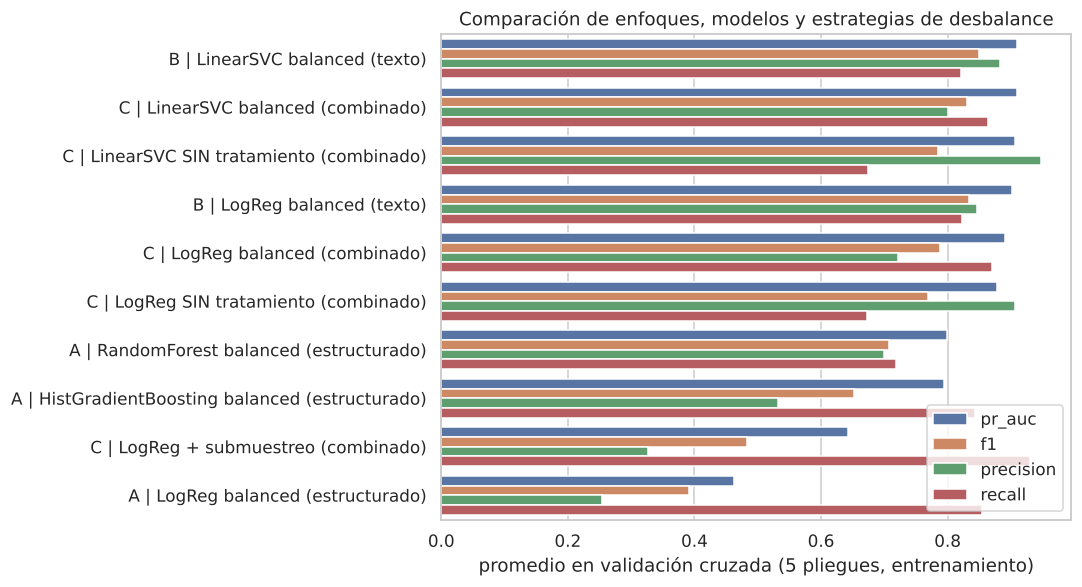

In [21]:
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_df = res[["pr_auc", "f1", "precision", "recall"]].reset_index().melt(id_vars="index")
sns.barplot(data=plot_df, y="index", x="value", hue="variable", ax=ax)
ax.set_ylabel(""); ax.set_xlabel("promedio en validación cruzada (5 pliegues, entrenamiento)")
ax.set_title("Comparación de enfoques, modelos y estrategias de desbalance"); ax.legend(loc="lower right")
savefig("09_comparacion_cv")

**Lectura de la tabla** (validación cruzada; el test todavía no se ha tocado):
* Comparar **A vs. B vs. C** responde si el texto aporta más que las variables estructuradas y si combinarlas
  ayuda.
* Comparar **sin tratamiento / balanced / submuestreo** muestra el efecto del desbalance: sin tratamiento suele
  tener alta precisión pero bajo *recall*; la ponderación sube el *recall*; el submuestreo descarta ~90 % de las
  ofertas legítimas y tiende a perder precisión.
* La **PR-AUC** no depende del umbral, así que es el criterio principal de selección; el F1 depende del umbral
  por defecto y se optimiza después (4.6).

### 4.5 Optimización de hiperparámetros (enfoque combinado)
Búsqueda en rejilla con validación cruzada estratificada y agrupada de 3 pliegues sobre el entrenamiento, optimizando
**PR-AUC**. Se ajusta la regularización `C` y el tamaño del n-grama. (En una primera corrida el óptimo quedó en el
borde de la rejilla, por lo que se amplió el rango de `C` hasta que el mejor valor quedara en el interior.)

In [22]:
CV3 = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
grids = {
    "LogReg": (Pipeline([("prep", prep_combined()), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
               {"clf__C": [4, 16, 64], "prep__txt__ngram_range": [(1, 1), (1, 2)]}),
    "LinearSVC": (Pipeline([("prep", prep_combined()), ("clf", LinearSVC(class_weight="balanced"))]),
                  {"clf__C": [0.3, 1.0, 3.0], "prep__txt__ngram_range": [(1, 1), (1, 2)]}),
}
best = {}
for name, (pipe, grid) in grids.items():
    t = time.time()
    gs = GridSearchCV(pipe, grid, scoring="average_precision", cv=CV3, n_jobs=1)
    gs.fit(X_train, y_train, groups=g_train)
    best[name] = gs
    print(f"{name}: mejor PR-AUC CV={gs.best_score_:.3f} con {gs.best_params_} ({time.time()-t:.0f}s)")
    display(pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]]
            .sort_values("mean_test_score", ascending=False).round(4))

LogReg: mejor PR-AUC CV=0.859 con {'clf__C': 16, 'prep__txt__ngram_range': (1, 2)} (91s)


,params,mean_test_score,std_test_score
3,"{'clf__C': 16, 'prep__txt__ngram_range': (1, 2)}",0.8587,0.0084
5,"{'clf__C': 64, 'prep__txt__ngram_range': (1, 2)}",0.8558,0.0079
1,"{'clf__C': 4, 'prep__txt__ngram_range': (1, 2)}",0.8401,0.0138
2,"{'clf__C': 16, 'prep__txt__ngram_range': (1, 1)}",0.8347,0.0061
4,"{'clf__C': 64, 'prep__txt__ngram_range': (1, 1)}",0.8300,0.0114
0,"{'clf__C': 4, 'prep__txt__ngram_range': (1, 1)}",0.8165,0.0154


LinearSVC: mejor PR-AUC CV=0.876 con {'clf__C': 3.0, 'prep__txt__ngram_range': (1, 2)} (99s)


,params,mean_test_score,std_test_score
5,"{'clf__C': 3.0, 'prep__txt__ngram_range': (1, 2)}",0.8759,0.0100
3,"{'clf__C': 1.0, 'prep__txt__ngram_range': (1, 2)}",0.8751,0.0094
1,"{'clf__C': 0.3, 'prep__txt__ngram_range': (1, 2)}",0.8620,0.0130
4,"{'clf__C': 3.0, 'prep__txt__ngram_range': (1, 1)}",0.8538,0.0089
2,"{'clf__C': 1.0, 'prep__txt__ngram_range': (1, 1)}",0.8520,0.0067
0,"{'clf__C': 0.3, 'prep__txt__ngram_range': (1, 1)}",0.8362,0.0136


### 4.6 Ajuste del umbral de decisión (sin tocar el test)
El umbral por defecto (0.5 en probabilidad, 0 en la SVM) no es necesariamente el óptimo con desbalance.
Se obtienen puntajes **out-of-fold** sobre el entrenamiento y se elige el umbral que maximiza el F1. Ese umbral
se aplica luego, tal cual, al conjunto de prueba.

In [23]:
def scores_of(model, Xd):
    return model.predict_proba(Xd)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(Xd)

thresholds = {}
for name, gs in best.items():
    method = "predict_proba" if name == "LogReg" else "decision_function"
    oof = cross_val_predict(gs.best_estimator_, X_train, y_train, groups=g_train, cv=CV3, method=method, n_jobs=1)
    oof = oof[:, 1] if oof.ndim == 2 else oof
    p, r, t = precision_recall_curve(y_train, oof)
    f1s = 2 * p * r / (p + r + 1e-12)
    i = np.nanargmax(f1s[:-1])
    thresholds[name] = t[i]
    print(f"{name}: umbral óptimo OOF = {t[i]:.3f} → F1={f1s[i]:.3f} (P={p[i]:.3f}, R={r[i]:.3f})")

LogReg: umbral óptimo OOF = 0.540 → F1=0.773 (P=0.792, R=0.755)


LinearSVC: umbral óptimo OOF = -0.256 → F1=0.800 (P=0.792, R=0.807)


### 4.7 Evaluación final en el conjunto de prueba

In [24]:
final_models = {n: gs.best_estimator_ for n, gs in best.items()}
# referencia estructurada: el mejor del enfoque A en CV (Random Forest), reentrenado con todo el entrenamiento
struct_ref = Pipeline([("prep", prep_structured()), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                       class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]).fit(X_train, y_train)

rows, test_scores = [], {}
def eval_test(name, model, thr=None):
    s = scores_of(model, X_test); test_scores[name] = s
    default_thr = 0.5 if hasattr(model, "predict_proba") else 0.0
    for label, th in [("umbral por defecto", default_thr)] + ([("umbral ajustado (OOF)", thr)] if thr is not None else []):
        pred = (s >= th).astype(int)
        rows.append({"modelo": name, "umbral": label, "valor_umbral": round(float(th), 3),
                     "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                     "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, s),
                     "pr_auc": average_precision_score(y_test, s)})

eval_test("RandomForest (estructurado)", struct_ref)
for n, m in final_models.items():
    eval_test(f"{n} (texto+estructurado)", m, thresholds[n])
test_res = pd.DataFrame(rows)
test_res.round(3)

,modelo,umbral,valor_umbral,precision,recall,f1,roc_auc,pr_auc
0,RandomForest (estructurado),umbral por defecto,0.500,0.663,0.749,0.703,0.982,0.825
1,LogReg (texto+estructurado),umbral por defecto,0.500,0.830,0.883,0.856,0.992,0.924
2,LogReg (texto+estructurado),umbral ajustado (OOF),0.540,0.838,0.877,0.857,0.992,0.924
3,LinearSVC (texto+estructurado),umbral por defecto,0.000,0.928,0.825,0.873,0.991,0.931
4,LinearSVC (texto+estructurado),umbral ajustado (OOF),-0.256,0.815,0.877,0.845,0.991,0.931


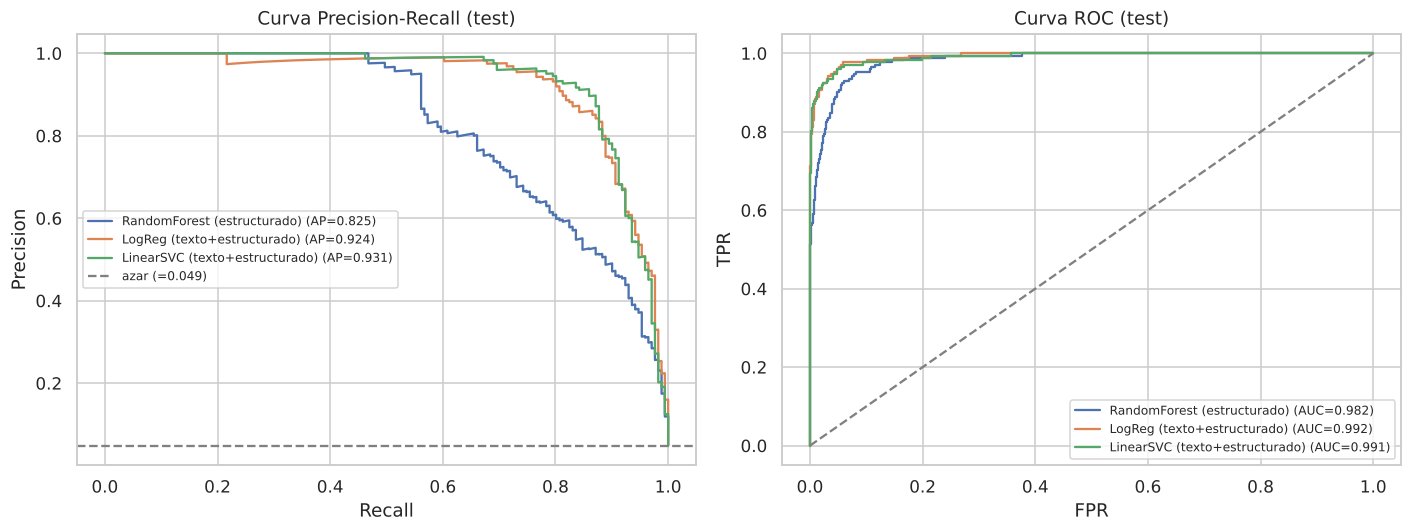

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n, s in test_scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    axes[0].plot(r, p, label=f"{n} (AP={average_precision_score(y_test, s):.3f})")
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[1].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, s):.3f})")
axes[0].axhline(y_test.mean(), ls="--", c="gray", label=f"azar (={y_test.mean():.3f})")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall (test)")
axes[1].plot([0, 1], [0, 1], "--", c="gray"); axes[1].set(xlabel="FPR", ylabel="TPR", title="Curva ROC (test)")
for a in axes: a.legend(fontsize=8)
savefig("10_curvas_pr_roc")

In [ ]:
best_name = max(best, key=lambda n: best[n].best_score_)
# Selección por validación de entrenamiento; test solo estima desempeño.
best_model, best_thr = final_models[best_name], thresholds[best_name]
s_best = test_scores[f"{best_name} (texto+estructurado)"]
y_pred = (s_best >= best_thr).astype(int)
print("Modelo seleccionado:", best_name, "| umbral:", round(float(best_thr), 3))
print(classification_report(y_test, y_pred, target_names=["Legítima", "Fraude"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Legítima", "Fraude"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Conteos")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"), display_labels=["Legítima", "Fraude"]).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2%")
axes[1].set_title("Normalizada por clase real")
plt.suptitle(f"Matriz de confusión (test) — {best_name}")
savefig("11_matriz_confusion")

### 4.8 ¿Qué aprende el modelo? Interpretación de variables

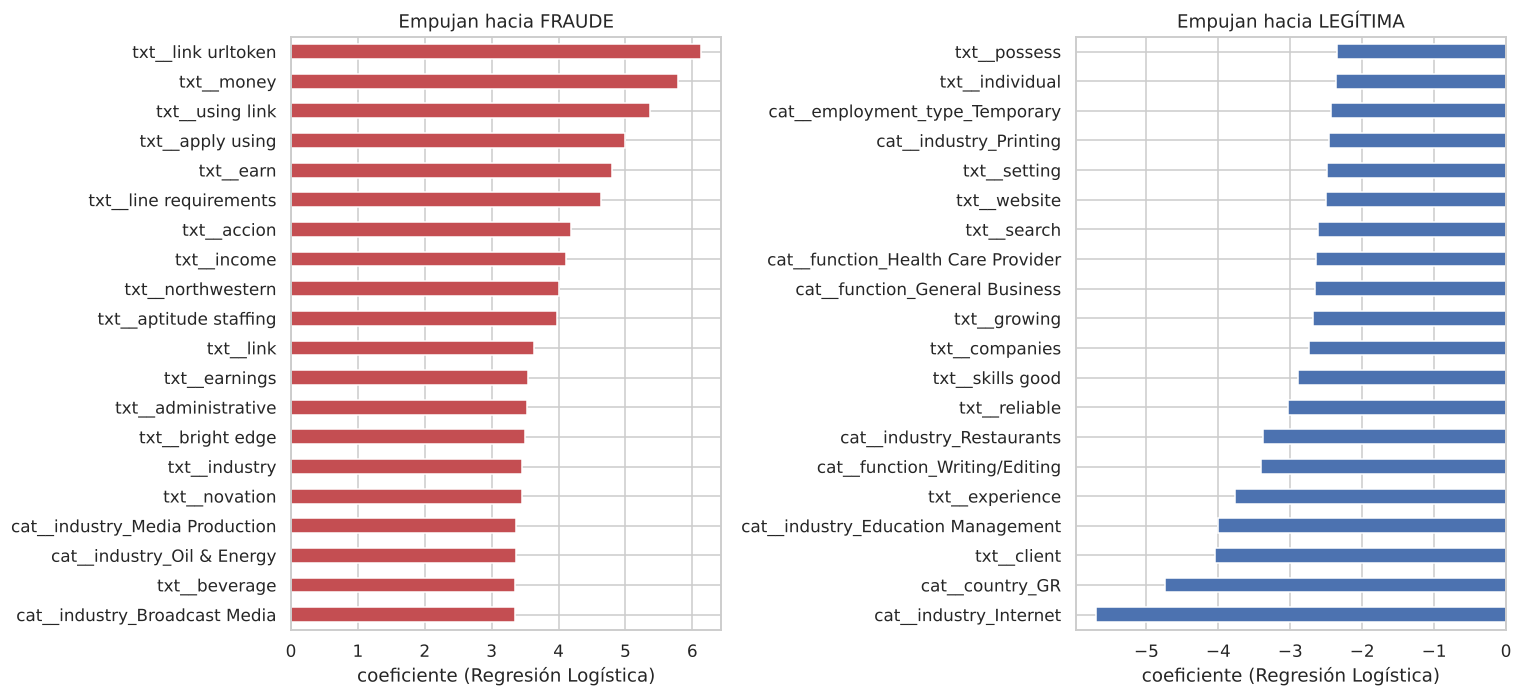

In [27]:
lr = final_models["LogReg"]
names = lr.named_steps["prep"].get_feature_names_out()
coef = lr.named_steps["clf"].coef_.ravel()
order = np.argsort(coef)
top_pos = pd.Series(coef[order[-20:]], index=names[order[-20:]])
top_neg = pd.Series(coef[order[:20]], index=names[order[:20]])
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
top_pos.plot.barh(ax=axes[0], color="#C44E52"); axes[0].set_title("Empujan hacia FRAUDE")
top_neg.plot.barh(ax=axes[1], color="#4C72B0"); axes[1].set_title("Empujan hacia LEGÍTIMA")
for a in axes: a.set_xlabel("coeficiente (Regresión Logística)")
savefig("12_coeficientes_lr")

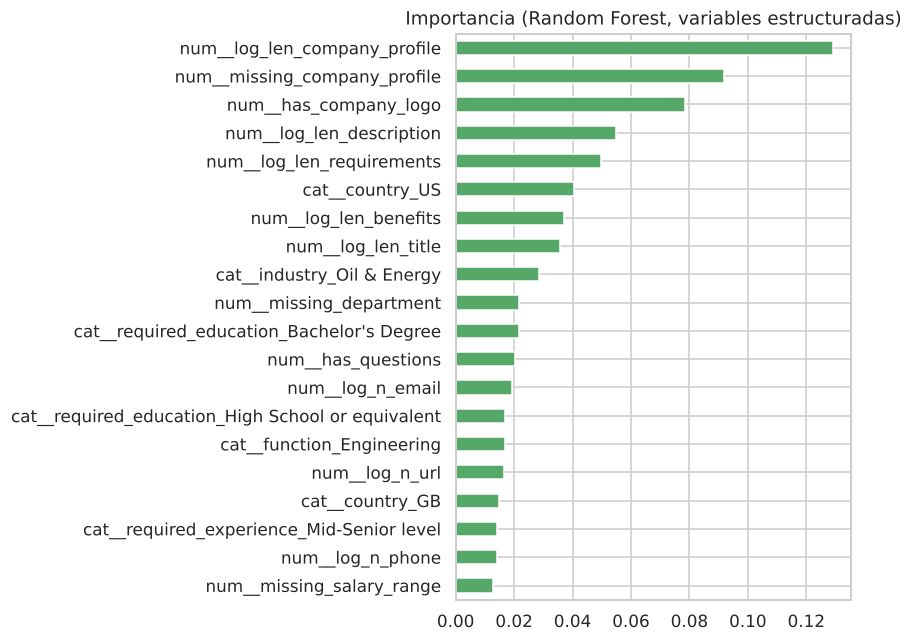

In [28]:
rf_imp = struct_ref
imp = pd.Series(rf_imp.named_steps["clf"].feature_importances_,
                index=rf_imp.named_steps["prep"].get_feature_names_out()).sort_values().tail(20)
imp.plot.barh(figsize=(8, 6), color="#55A868"); plt.title("Importancia (Random Forest, variables estructuradas)")
savefig("13_importancia_rf")

### 4.9 Análisis de errores

In [29]:
err = X_test.copy(); err["y"] = y_test; err["pred"] = y_pred; err["score"] = s_best
show_cols = ["score", "employment_type", "industry", "country", "has_company_logo", "has_questions"]
print("FALSOS NEGATIVOS (fraudes no detectados) — los de menor puntaje:")
display(df.loc[err[(err.y == 1) & (err.pred == 0)].sort_values("score").index[:5], ["title"]].join(err[show_cols]))
print("FALSOS POSITIVOS (legítimas marcadas como fraude) — los de mayor puntaje:")
display(df.loc[err[(err.y == 0) & (err.pred == 1)].sort_values("score", ascending=False).index[:5], ["title"]].join(err[show_cols]))

FALSOS NEGATIVOS (fraudes no detectados) — los de menor puntaje:


,title,score,employment_type,industry,country,has_company_logo,has_questions
9067,Front-End/JavaScript Engineer,-1.436834,Missing,Missing,ID,0,1
1198,Big Data Engineer,-1.204384,Contract,Information Technology and Services,US,0,0
8006,Marketing/sales Coordinator,-1.174691,Full-time,Marketing and Advertising,US,0,0
17461,Brand & Logo Design Contest,-1.054010,Other,Missing,US,0,0
144,Forward Cap.,-0.966792,Missing,Missing,Missing,0,0


FALSOS POSITIVOS (legítimas marcadas como fraude) — los de mayor puntaje:


,title,score,employment_type,industry,country,has_company_logo,has_questions
6261,Data Entry,0.988369,Contract,Missing,US,0,0
8140,Accounting Clerk $15/hr,0.506225,Full-time,Accounting,US,0,0
5281,Administrative Assistant/Front Desk Clerk,0.439078,Missing,Missing,US,0,0
6708,Customer Service Representative,0.410369,Full-time,Insurance,US,1,0
6756,Customer Service Representative,0.410369,Full-time,Insurance,US,1,0


**Costos de los errores:**
* **Falso negativo** (fraude no detectado): una persona puede entregar documentos, datos bancarios o pagar una
  "tarifa"; además daña la reputación de la plataforma. Es el error más grave.
* **Falso positivo** (legítima marcada): una empresa real ve su oferta retenida; es molesto, pero se resuelve con
  **revisión humana**.

Por eso conviene usar el modelo como **sistema de priorización**: un umbral relativamente bajo (más *recall*)
y revisión manual de lo marcado. El umbral puede moverse sobre la curva PR según la capacidad del equipo de
moderación (figura 10).

## 5. Componente no supervisado

**Objetivo:** descubrir temáticas en las publicaciones **sin usar la etiqueta** y luego verificar si algún
grupo concentra fraude.

**Representación:** TF-IDF del texto limpio → **LSA** (`TruncatedSVD`, 100 componentes) → normalización L2.
LSA reduce ruido, agrupa sinónimos en componentes latentes y hace viable el agrupamiento en 17 mil documentos
(el TF-IDF tiene decenas de miles de dimensiones dispersas y las distancias euclidianas pierden sentido ahí).

**Sobre la fuga de información:** aquí la etiqueta **no se usa** en ninguna transformación ni en el
agrupamiento; por eso se ajusta sobre todo el corpus (el objetivo es describir los datos, no predecir sobre datos
nuevos). `fraudulent` solo se usa **a posteriori** para interpretar.

| Algoritmo | Justificación | Supuestos | Ventajas | Limitaciones |
|---|---|---|---|---|
| **K-Means** (sobre LSA normalizado ≈ similitud coseno) | Estándar para agrupar documentos; escala a todo el corpus. | Grupos convexos, de tamaño y varianza parecidos; hay que fijar *k*. | Rápido, centroides interpretables como "temas". | Sensible a la inicialización y a *k*; asigna todo punto a algún grupo. |
| **Aglomerativo (Ward)** | Visión jerárquica; no depende de una inicialización aleatoria. | Ward minimiza la varianza intra-grupo (distancia euclidiana). | Determinista, permite ver la estructura jerárquica. | Memoria O(n²) → se usa una muestra estratificada de 6 000 documentos. |
| **NMF** (modelo de tópicos, complementario) | Descompone TF-IDF en tópicos aditivos y legibles. | Datos no negativos. | Tópicos muy interpretables; asignación "suave". | Requiere fijar número de tópicos. |
| **Isolation Forest** (anomalías, complementario) | Pregunta si el fraude es "atípico" en el espacio textual. | Las anomalías son pocas y fáciles de aislar. | Sin etiquetas, puntaje continuo. | El fraude puede parecerse a ofertas normales. |

TF-IDF: (17599, 16779) → LSA: (17599, 100) | varianza explicada acumulada: 27.9%


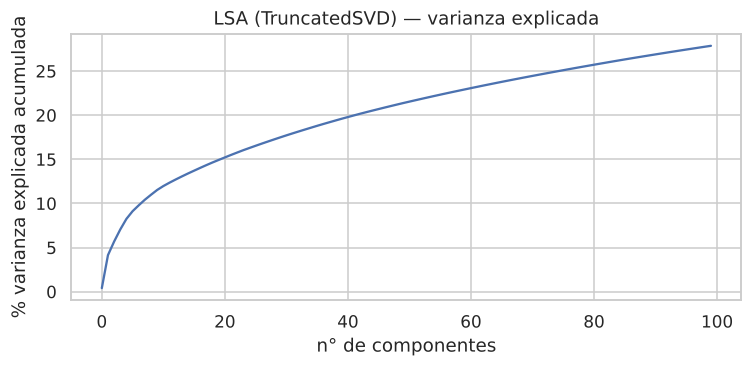

In [30]:
tfidf_u = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True, max_features=30000)
T = tfidf_u.fit_transform(df["text"])
terms_u = np.array(tfidf_u.get_feature_names_out())
svd = TruncatedSVD(n_components=100, random_state=SEED)
Z = Normalizer().fit_transform(svd.fit_transform(T))
print("TF-IDF:", T.shape, "→ LSA:", Z.shape, f"| varianza explicada acumulada: {svd.explained_variance_ratio_.sum():.1%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.cumsum(svd.explained_variance_ratio_) * 100)
ax.set(xlabel="n° de componentes", ylabel="% varianza explicada acumulada", title="LSA (TruncatedSVD) — varianza explicada")
savefig("14_svd_varianza")

### 5.1 Selección del número de grupos *k*

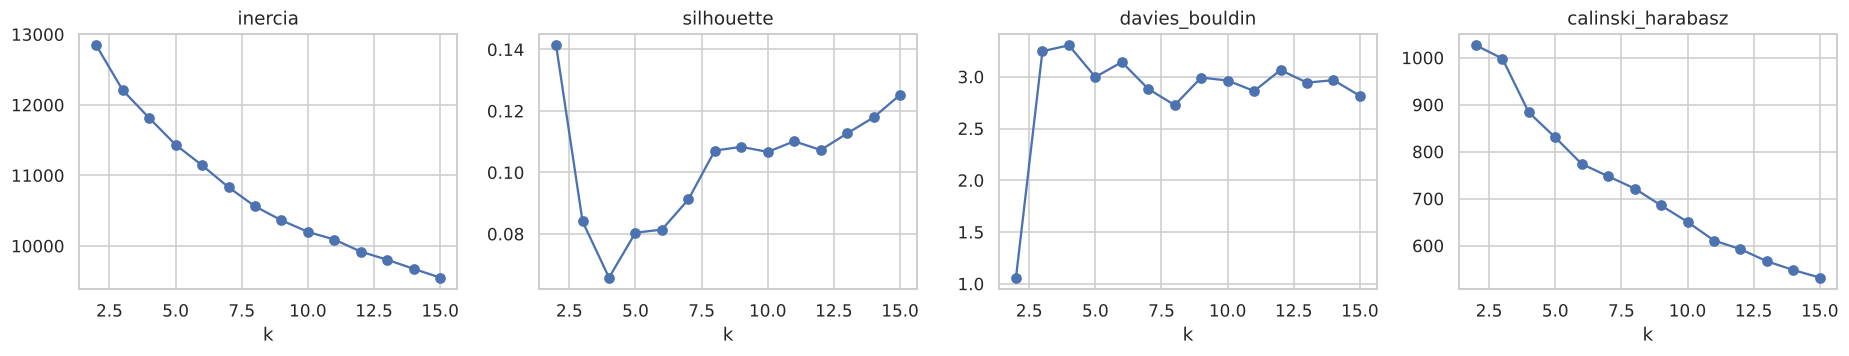

,inercia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,12844.597,0.141,1.060,1026.480
3,12208.464,0.084,3.247,998.384
4,11813.917,0.066,3.304,883.649
5,11434.877,0.080,2.997,830.467
6,11142.890,0.081,3.142,773.944
7,10831.828,0.091,2.882,747.637
8,10561.248,0.107,2.726,721.595
9,10362.718,0.108,2.992,685.580
10,10199.135,0.107,2.964,650.488


In [31]:
ks = range(2, 16)
sel = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    sel.append({"k": k, "inercia": km.inertia_,
                "silhouette": silhouette_score(Z, km.labels_, sample_size=6000, random_state=SEED),
                "davies_bouldin": davies_bouldin_score(Z, km.labels_),
                "calinski_harabasz": calinski_harabasz_score(Z, km.labels_)})
sel = pd.DataFrame(sel).set_index("k")
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for a, c in zip(axes, sel.columns):
    a.plot(sel.index, sel[c], marker="o"); a.set_title(c); a.set_xlabel("k")
savefig("15_seleccion_k")
sel.round(3)

In [32]:
# Criterio: entre k=4..12 (rango útil para describir temáticas), el k con mejor silhouette;
# se reporta también Davies-Bouldin (menor es mejor) para confirmar.
K = int(sel.loc[4:12, "silhouette"].idxmax())
print("k elegido:", K)

k elegido: 11


**Nota:** en texto es normal que la *silhouette* sea baja (≈0.05–0.15): las temáticas se solapan y los
documentos comparten vocabulario general. Por eso la elección de *k* combina métricas internas con la
**interpretabilidad** de los grupos (términos representativos), que es el objetivo del componente.

### 5.2 K-Means: entrenamiento, estabilidad y métricas

In [33]:
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
df["cluster_km"] = km.labels_

# Estabilidad: ARI entre corridas con distintas semillas
runs = [KMeans(n_clusters=K, n_init=1, random_state=s).fit_predict(Z) for s in range(5)]
ari_runs = [adjusted_rand_score(runs[i], runs[j]) for i in range(5) for j in range(i + 1, 5)]
print(f"Estabilidad K-Means (ARI entre 5 semillas): media={np.mean(ari_runs):.3f}, mín={np.min(ari_runs):.3f}")

Estabilidad K-Means (ARI entre 5 semillas): media=0.578, mín=0.447


### 5.3 Agrupamiento jerárquico aglomerativo (Ward)

In [34]:
_, idx_s = train_test_split(np.arange(len(df)), test_size=6000, stratify=y, random_state=SEED)
Zs = Z[idx_s]
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Zs)

unsup_metrics = pd.DataFrame({
    "K-Means": {"silhouette": silhouette_score(Zs, km.labels_[idx_s]),
                "davies_bouldin": davies_bouldin_score(Zs, km.labels_[idx_s]),
                "calinski_harabasz": calinski_harabasz_score(Zs, km.labels_[idx_s]),
                "ARI vs etiqueta": adjusted_rand_score(y[idx_s], km.labels_[idx_s]),
                "NMI vs etiqueta": normalized_mutual_info_score(y[idx_s], km.labels_[idx_s])},
    "Aglomerativo Ward": {"silhouette": silhouette_score(Zs, agg.labels_),
                          "davies_bouldin": davies_bouldin_score(Zs, agg.labels_),
                          "calinski_harabasz": calinski_harabasz_score(Zs, agg.labels_),
                          "ARI vs etiqueta": adjusted_rand_score(y[idx_s], agg.labels_),
                          "NMI vs etiqueta": normalized_mutual_info_score(y[idx_s], agg.labels_)},
}).T
print(f"Acuerdo K-Means vs Ward (ARI, misma muestra): {adjusted_rand_score(km.labels_[idx_s], agg.labels_):.3f}")
unsup_metrics.round(3)

Acuerdo K-Means vs Ward (ARI, misma muestra): 0.298


,silhouette,davies_bouldin,calinski_harabasz,ARI vs etiqueta,NMI vs etiqueta
K-Means,0.105,2.860,209.889,-0.004,0.024
Aglomerativo Ward,0.081,2.769,177.972,-0.011,0.018


*Métricas calculadas sobre la misma muestra de 6 000 documentos para que la comparación sea justa.*
ARI y NMI frente a la etiqueta **se esperan cercanos a 0**: los grupos describen **temas** (ventas, TI, salud,
atención al cliente…), no "fraude vs. legítimo". La pregunta relevante es si **algún tema concentra fraude**.

### 5.4 Interpretación de los grupos (K-Means)

In [35]:
centroids_terms = svd.inverse_transform(km.cluster_centers_)
profile = df.groupby("cluster_km").agg(n=("fraudulent", "size"), tasa_fraude=("fraudulent", "mean"),
                                       pct_sin_logo=("has_company_logo", lambda s: 1 - s.mean()),
                                       pct_teletrabajo=("telecommuting", "mean"))
profile["lift_fraude"] = profile["tasa_fraude"] / df["fraudulent"].mean()
profile["top_terminos"] = [", ".join(terms_u[np.argsort(centroids_terms[c])[::-1][:10]]) for c in profile.index]
profile["funcion_mas_comun"] = df.groupby("cluster_km")["function"].agg(lambda s: s[s != "Missing"].mode().iat[0] if (s != "Missing").any() else "Missing")
profile["ejemplos_titulo"] = [" | ".join(df.loc[df.cluster_km == c, "title"].sample(3, random_state=SEED).astype(str)) for c in profile.index]
pd.set_option("display.max_colwidth", 120)
profile.sort_values("tasa_fraude", ascending=False).round(3)

,n,tasa_fraude,pct_sin_logo,pct_teletrabajo,lift_fraude,top_terminos,funcion_mas_comun,ejemplos_titulo
cluster_km,,,,,,,,
1,1996,0.168,0.324,0.021,3.451,"management, ability, office, support, required, position, duties, accounting, including, knowledge",Administrative,ACCOUNTING SUPERVISOR | Health and Safety Manager | Maintenance Tech II (KC)
6,3307,0.101,0.234,0.043,2.076,"service, home, position, services, care, benefits, customer, job, training, hours",Customer Service,High School Mathematics Teacher | Nurse Practitioner | Web Agency Sales and Business Development Associate
5,1856,0.034,0.220,0.067,0.709,"sales, business, customer, marketing, new, customers, management, clients, service, market",Sales,Alliance Manager | Strategic Account Director - San Francisco | Business Development Manager
7,2035,0.032,0.255,0.043,0.657,"software, development, systems, data, technical, design, solutions, engineer, business, sql",Information Technology,"Lead Business Intelligence / Business Objects (BOBJ) | Data Analyst | Junior Software Engineers, C++ for AUTOMOTIVE"
0,2588,0.012,0.053,0.044,0.254,"people, ll, looking, product, want, great, new, working, world, like",Engineering,Cook/Food Prep | Product Marketing Entrepreneur | Network Marketing
10,1890,0.007,0.189,0.087,0.152,"web, developer, design, development, java, html, css, mobile, software, end",Information Technology,Android Developer | Front End Developer | Software Engineer (Java)
8,1635,0.007,0.097,0.047,0.138,"marketing, media, social, digital, content, campaigns, online, creative, new, strategy",Marketing,Account Manager | Social Media and Editorial Intern for Krrb.com (Paid) | Marketing Intern (Paid)
9,626,0.002,0.998,0.000,0.033,"website, jobs, search, manufacturing, technical, apply, redirect, openings, job, medium",Engineering,Food Quality | Manufacturing Engineering Manager | .NET Developer
2,540,0.000,0.000,0.000,0.000,"productivity, document, customer, mail, increase, enterprise, communications, improve, processes, perform",Customer Service,Customer Service Technical Specialist | Customer Service Associate | Driver I


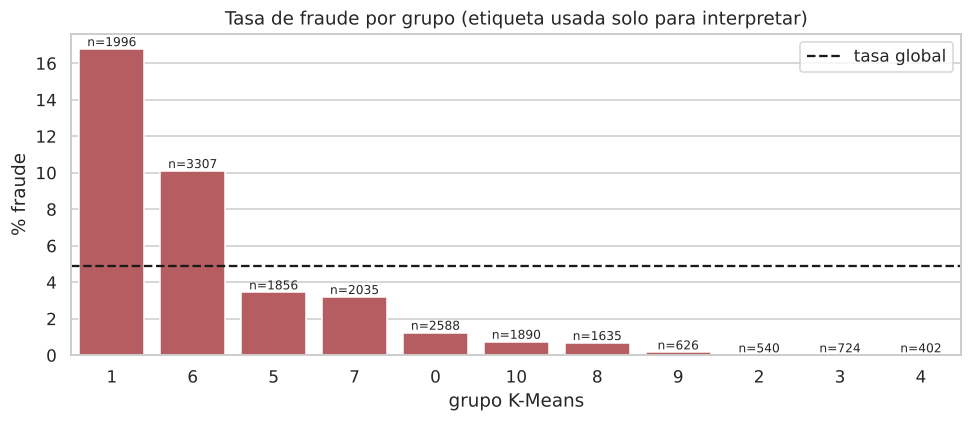

In [36]:
fig, ax = plt.subplots(figsize=(9, 4))
p_ = profile.sort_values("tasa_fraude", ascending=False)
sns.barplot(x=p_.index.astype(str), y=p_["tasa_fraude"] * 100, ax=ax, color="#C44E52", order=p_.index.astype(str))
ax.axhline(df["fraudulent"].mean() * 100, ls="--", c="k", label="tasa global")
for i, (t, n) in enumerate(zip(p_["tasa_fraude"], p_["n"])):
    ax.text(i, t * 100, f"n={n}", ha="center", va="bottom", fontsize=8)
ax.set(xlabel="grupo K-Means", ylabel="% fraude", title="Tasa de fraude por grupo (etiqueta usada solo para interpretar)"); ax.legend()
savefig("16_fraude_por_cluster")

### 5.5 Tópicos con NMF (complementario)

In [37]:
N_TOP = 10
nmf = NMF(n_components=N_TOP, random_state=SEED, init="nndsvda", max_iter=400)
W = nmf.fit_transform(T)
topics = pd.DataFrame({
    "top_terminos": [", ".join(terms_u[np.argsort(comp)[::-1][:10]]) for comp in nmf.components_],
})
df["topic_nmf"] = W.argmax(axis=1)
t_stats = df.groupby("topic_nmf")["fraudulent"].agg(n="size", tasa_fraude="mean")
topics = topics.join(t_stats); topics["lift_fraude"] = topics["tasa_fraude"] / df["fraudulent"].mean()
topics.sort_values("tasa_fraude", ascending=False).round(3)

,top_terminos,n,tasa_fraude,lift_fraude
8,"home, lei, customer, sales, siding, enhancements, homeowners, representatives, remodeling, renovation",654,0.208,4.275
5,"tidewater, employment, disability, vacation, finance, insurance, paid, hours, credit, status",1110,0.126,2.593
0,"management, business, sales, client, services, ability, support, provide, strong, needs",4885,0.083,1.709
4,"website, search, jobs, manufacturing, apply, redirect, openings, click, technical, job",785,0.050,1.021
2,"mail, productivity, document, customer, increase, enterprise, communications, adhere, perform, assigned",603,0.040,0.818
7,"web, developer, design, development, software, java, applications, technologies, sql, html",4202,0.016,0.333
6,"shall, conflict, fails, deeper, digital, stories, content, broadcast, news, journalism",256,0.016,0.321
3,"apprenticeship, recruitment, olds, career, education, consultants, long, wishing, sellers, official",473,0.011,0.217
9,"people, marketing, ll, looking, great, want, media, new, world, like",3882,0.009,0.180
1,"abroad, jobs, airfare, celta, tesol, tefl, passport, housing, teacher, teachers",749,0.000,0.000


Correspondencia K-Means vs. tópico NMF dominante (NMI): 0.556


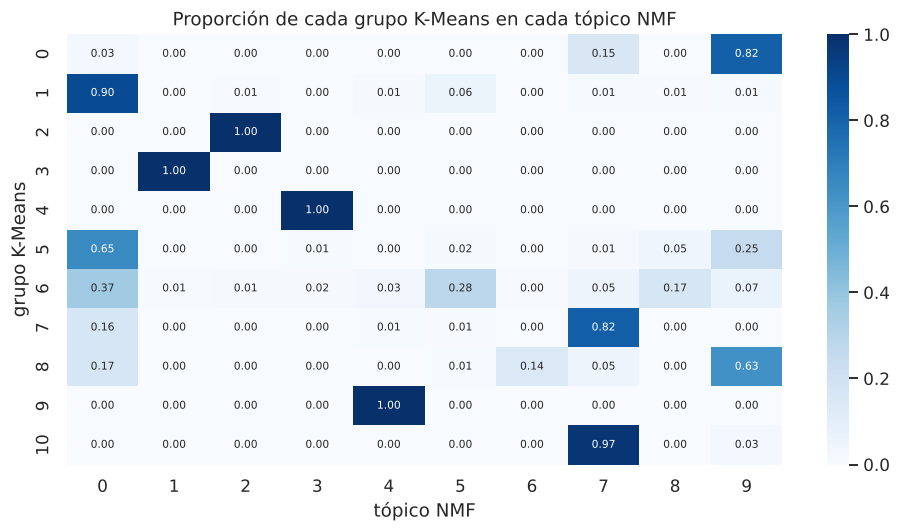

In [38]:
print("Correspondencia K-Means vs. tópico NMF dominante (NMI):",
      round(normalized_mutual_info_score(df["cluster_km"], df["topic_nmf"]), 3))
ct = pd.crosstab(df["cluster_km"], df["topic_nmf"], normalize="index")
plt.figure(figsize=(9, 5)); sns.heatmap(ct, cmap="Blues", annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Proporción de cada grupo K-Means en cada tópico NMF"); plt.xlabel("tópico NMF"); plt.ylabel("grupo K-Means")
savefig("17_kmeans_vs_nmf")

### 5.6 ¿El fraude es una anomalía textual? (Isolation Forest)

In [39]:
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=SEED).fit(Z)
anom = -iso.score_samples(Z)
print(f"PR-AUC del puntaje de anomalía vs fraude: {average_precision_score(y, anom):.3f} (azar = {y.mean():.3f})")
print(f"ROC-AUC del puntaje de anomalía vs fraude: {roc_auc_score(y, anom):.3f}")
top5 = anom >= np.quantile(anom, 0.95)
print(f"Tasa de fraude en el 5% más anómalo: {y[top5].mean():.2%} (global {y.mean():.2%})")

PR-AUC del puntaje de anomalía vs fraude: 0.097 (azar = 0.049)
ROC-AUC del puntaje de anomalía vs fraude: 0.699
Tasa de fraude en el 5% más anómalo: 15.11% (global 4.86%)


## 6. Visualización y reducción de dimensionalidad
Se comparan tres proyecciones 2D de la representación LSA: **SVD (lineal)**, **t-SNE** y **UMAP** (no lineales),
coloreadas por grupo K-Means y por la etiqueta real. t-SNE y UMAP se calculan sobre la muestra de 6 000 documentos.

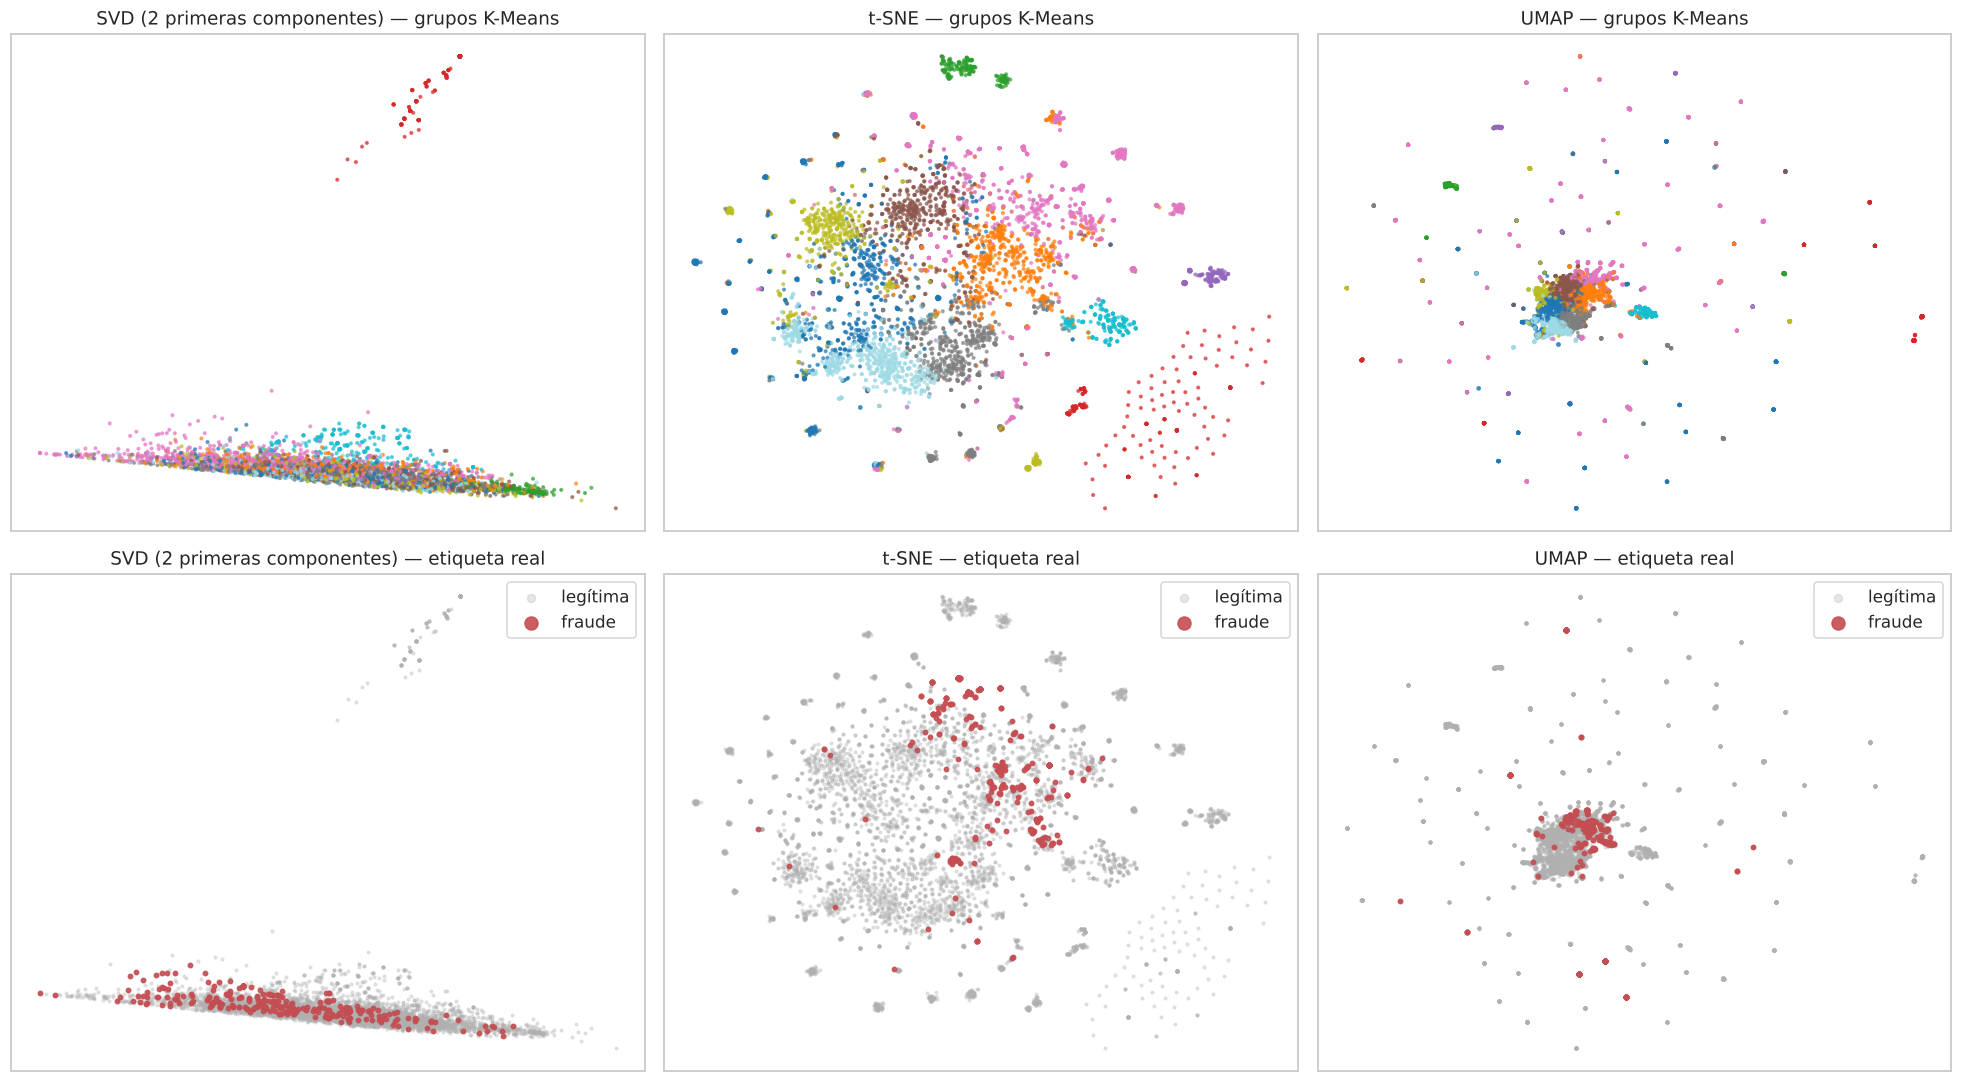

In [40]:
import umap
emb = {
    "SVD (2 primeras componentes)": svd.transform(T[idx_s])[:, :2],
    "t-SNE": TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(Zs),
    "UMAP": umap.UMAP(n_neighbors=30, min_dist=0.1, metric="cosine", random_state=SEED).fit_transform(Zs),
}
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
lab_s, y_s = km.labels_[idx_s], y[idx_s]
for j, (name, E) in enumerate(emb.items()):
    axes[0, j].scatter(E[:, 0], E[:, 1], c=lab_s, cmap="tab20", s=3, alpha=0.6)
    axes[0, j].set_title(f"{name} — grupos K-Means")
    axes[1, j].scatter(E[y_s == 0, 0], E[y_s == 0, 1], c="#B0B0B0", s=3, alpha=0.3, label="legítima")
    axes[1, j].scatter(E[y_s == 1, 0], E[y_s == 1, 1], c="#C44E52", s=8, alpha=0.9, label="fraude")
    axes[1, j].set_title(f"{name} — etiqueta real"); axes[1, j].legend(markerscale=3)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
savefig("18_proyecciones_2d")

**¿Qué se conserva y qué se pierde?**
* **SVD/LSA** es lineal: las 2 primeras componentes conservan solo una fracción pequeña de la varianza (figura 14),
  por lo que los grupos se ven muy solapados. Con 100 componentes se conserva suficiente estructura para agrupar.
* **t-SNE** conserva vecindarios **locales**: los grupos se ven como "islas" bien definidas, pero las distancias
  entre islas y sus tamaños **no** son interpretables.
* **UMAP** conserva vecindarios locales y algo más de la estructura **global**; en este corpus comprimió la mayoría de
  las ofertas en un núcleo denso y dejó las plantillas como puntos aislados, así que t-SNE resultó más legible.
* En las tres proyecciones el fraude **no forma una isla propia**: en t-SNE se ve concentrado en una región (la de
  administración / atención al cliente), pero mezclado con ofertas legítimas. Esto coincide con el ARI ≈ 0 y explica por qué el componente supervisado es necesario para detectarlo.

## 7. Análisis comparativo entre aprendizaje supervisado y no supervisado

Resumen numérico de ambos componentes (calculado en la celda siguiente) y respuestas a las 8 preguntas de la guía.

In [41]:
summary = {
    "Fraude en el dataset": f"{y.mean():.2%}",
    "Mejor modelo supervisado": best_name,
    "PR-AUC test": f"{average_precision_score(y_test, s_best):.3f}",
    "ROC-AUC test": f"{roc_auc_score(y_test, s_best):.3f}",
    "Precision / Recall / F1 test (umbral ajustado)": f"{precision_score(y_test, y_pred):.3f} / {recall_score(y_test, y_pred):.3f} / {f1_score(y_test, y_pred):.3f}",
    "k K-Means": K,
    "Silhouette K-Means / Ward": f"{unsup_metrics.loc['K-Means','silhouette']:.3f} / {unsup_metrics.loc['Aglomerativo Ward','silhouette']:.3f}",
    "Grupo con mayor tasa de fraude": f"{profile['tasa_fraude'].idxmax()} ({profile['tasa_fraude'].max():.1%}, lift {profile['lift_fraude'].max():.1f}x)",
    "PR-AUC Isolation Forest": f"{average_precision_score(y, anom):.3f}",
}
pd.Series(summary, name="valor").to_frame()

,valor
Fraude en el dataset,4.86%
Mejor modelo supervisado,LinearSVC
PR-AUC test,0.931
ROC-AUC test,0.991
Precision / Recall / F1 test (umbral ajustado),0.815 / 0.877 / 0.845
k K-Means,11
Silhouette K-Means / Ward,0.105 / 0.081
Grupo con mayor tasa de fraude,"1 (16.8%, lift 3.5x)"
PR-AUC Isolation Forest,0.097


### 7.1 Respuestas a las preguntas de la guía

**1. ¿Qué problema resuelve cada componente?**
El **supervisado** responde a *"¿esta oferta concreta es fraudulenta?"*: aprende, a partir de ejemplos etiquetados,
una función que asigna un puntaje de riesgo a cada publicación nueva. El **no supervisado** responde a *"¿qué tipos
de publicaciones existen y cómo se organizan?"*: sin mirar la etiqueta, describe temáticas (administración, atención
al cliente, ventas, TI, marketing, plantillas de agencias…) y solo después se pregunta en cuáles se concentra el
fraude. El primero es una herramienta de **decisión**; el segundo, de **exploración y comprensión**.

**2. ¿Qué algoritmos se seleccionaron y por qué?**
* *Supervisado:* **Regresión Logística** y **SVM lineal** sobre TF-IDF (+ estructuradas), porque los modelos lineales
  son el estándar en texto de alta dimensión y disperso (16–50 mil columnas): entrenan en segundos, se regularizan
  bien y son interpretables. **Random Forest** y **HistGradientBoosting** se usaron en el enfoque estructurado porque
  capturan interacciones entre indicadores (sin logo × sin perfil × industria) y no requieren escalar.
* *No supervisado:* **K-Means** sobre LSA normalizado (se relaciona con la similitud coseno, aunque K-Means estándar no equivale exactamente a spherical K-Means, escala a 17 mil
  documentos y sus centroides se leen como temas) y **aglomerativo Ward** (determinista, jerárquico, sirve para
  contrastar la estabilidad de K-Means). **NMF** e **Isolation Forest** se añadieron como complemento: NMF da tópicos
  más legibles e Isolation Forest prueba la hipótesis "el fraude es una anomalía textual".

**3. ¿Qué dificultades se presentaron?**
* **Desbalance (4,9 % de fraude):** la *accuracy* es insuficiente por sí sola (98,4 % para nuestro modelo, pero 95 % para uno que nunca
  detecta fraude). Se resolvió con métricas de la clase positiva (PR-AUC, F1), ponderación de clases y ajuste de
  umbral. El submuestreo resultó contraproducente (PR-AUC 0,64 vs 0,89 con ponderación): descarta ~90 % de las
  ofertas legítimas y con ellas mucho vocabulario útil.
* **Duplicados y fuga de información:** 281 duplicados exactos y ~1 800 ofertas con texto repetido. Con una
  partición aleatoria simple las métricas salían infladas (en una primera corrida el F1 de prueba llegó a 0,92). Se
  corrigió con partición y validación **agrupadas por texto** (`StratifiedGroupKFold`).
* **Alta cardinalidad y faltantes informativos:** `location` (3 105 valores), `department` (1 337) y `salary_range`
  (874). Se resolvió extrayendo el país, agrupando categorías raras y usando indicadores de faltante.
* **Agrupamiento de texto:** las *silhouette* son bajas (≈0,10) y K-Means es moderadamente inestable (ARI medio entre
  semillas = 0,58). Es típico de texto, donde los temas se solapan; por eso la interpretación se apoya en términos
  representativos y en la coincidencia con NMF (NMI = 0,56), no solo en métricas internas.
* **Selección de *k*:** la silhouette máxima está en k=2, pero esa partición solo separa un bloque de plantillas casi
  idénticas del resto y no describe temáticas. Se eligió k=11 (mejor silhouette en el rango 4–12, con Davies-Bouldin
  entre los más bajos).

**4. ¿El modelo supervisado identificó correctamente los casos de interés?**
Sí. La **SVM lineal con texto + variables estructuradas** obtuvo en el conjunto de prueba (3 520 ofertas, 171
fraudulentas, nunca vistas durante el ajuste) **PR-AUC = 0,931**, ROC-AUC = 0,991 y, con el umbral elegido por
validación cruzada, **Recall = 0,877, Precision = 0,815, F1 = 0,845**. La matriz de confusión muestra **150 de 171
fraudes detectados**, 21 no detectados y 34 falsas alarmas entre 3 349 ofertas legítimas (1 %). La línea base del
azar en PR-AUC es 0,049, por lo que su AP supera ampliamente esa referencia; el cociente no significa que detecte 19 veces más fraudes. Los resultados de prueba son
coherentes con la validación cruzada (PR-AUC 0,91 en 5 pliegues), aunque esta coincidencia no demuestra por sí sola ausencia de sobreajuste.

**5. ¿El modelo no supervisado descubrió estructuras que no eran evidentes?**
Sí, en dos sentidos:
* **El fraude se concentra temáticamente.** Sin usar etiquetas, dos grupos de K-Means —*administración / oficina /
  contabilidad* (16,8 % de fraude, *lift* 3,5×) y *atención al cliente / trabajo desde casa / cuidado* (10,1 %,
  *lift* 2,1×)— reúnen ≈ 30 % de las publicaciones pero ≈ 78 % de los fraudes. NMF encontró un tópico aún más
  específico (*home, siding, remodeling, homeowners*: 20,8 % de fraude, *lift* 4,3×).
* **Existen "plantillas" repetitivas** de agencias (enseñanza de inglés en el extranjero —TEFL/TESOL—, programas de
  aprendices, avisos que redirigen a otra web) que forman grupos compactos con **0 % de fraude**. Esto no era visible
  en el EDA y explica parte de los duplicados de texto.
* En cambio, el fraude **no es una anomalía textual**: Isolation Forest alcanza solo PR-AUC = 0,10 (el 5 % más anómalo
  tiene 15 % de fraude, 3× la base, pero detecta muy pocos casos). Las ofertas falsas imitan bien a las reales.

**6. ¿Qué relación hay entre las etiquetas y los grupos encontrados?**
Globalmente, **casi ninguna**: ARI ≈ 0 y NMI ≈ 0,02 para K-Means y Ward. Esto es lo esperado y no es un fracaso: los
grupos capturan el **tema** de la oferta (qué trabajo es), mientras que el fraude es una propiedad **transversal**
(cómo está escrita, qué promete, qué información omite). La relación aparece a nivel de **tasa de fraude por grupo**:
hay temas de riesgo alto (administración, atención al cliente, remodelación) y temas de riesgo prácticamente nulo
(desarrollo web, marketing digital, plantillas de agencias).

**7. ¿Qué información se conserva y se pierde con la reducción de dimensionalidad?**
* **LSA (100 componentes)** conserva el 28 % de la varianza del TF-IDF; parece poco, pero no podemos afirmar que la varianza descartada sea solo ruido; también puede contener información útil. Esas 100 dimensiones bastan para que los grupos sean interpretables. Se pierden matices
  finos: nombres de empresas, frases como *"apply using link"* y bigramas específicos que el modelo supervisado sí
  aprovecha.
* **Las 2 primeras componentes de SVD** muestran casi solo la dirección "plantillas vs. resto": son lineales y
  globales, así que todo lo demás se solapa.
* **t-SNE** conserva bien los vecindarios locales y fue la proyección más legible: muestra las plantillas como islas y
  el fraude **concentrado en una región** del mapa, aunque mezclado con ofertas legítimas. Sus distancias entre islas
  no son interpretables.
* **UMAP** comprimió la mayor parte de los datos en un núcleo denso y dejó las plantillas como puntos aislados: en este
  corpus preservó más estructura global pero fue menos informativo visualmente que t-SNE.

**8. ¿Qué enfoque recomendaríamos para una aplicación real?**
Recomendamos la **SVM lineal (o la Regresión Logística, si se necesitan probabilidades) con texto + variables
estructuradas como filtro de priorización**, no como bloqueador automático:
* Alto *recall* (≈88 %) con solo ~1 % de falsas alarmas sobre las legítimas: un equipo pequeño de moderación puede
  revisar lo marcado.
* Es rápido, barato de reentrenar y explicable (se puede mostrar al moderador qué palabras dispararon la alerta).
* El umbral debe fijarse según el costo: un fraude no detectado expone datos personales o dinero de una persona; una
  falsa alarma solo retrasa una publicación legítima. Con un umbral más bajo se gana *recall* a costa de revisar más.
* El **componente no supervisado** aporta como **capa complementaria**: los temas de alto riesgo pueden recibir
  revisión reforzada, y la detección de nuevos grupos permite descubrir esquemas de fraude que aún no están
  etiquetados.

### 7.2 Comparación final de modelos supervisados (conjunto de prueba)

| Modelo | Enfoque | PR-AUC | ROC-AUC | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| Random Forest | estructurado | 0,825 | 0,982 | 0,663 | 0,749 | 0,703 |
| Regresión Logística (C=16, 1-2 gramas) | texto + estructurado | 0,924 | 0,992 | 0,838 | 0,877 | 0,857 |
| **SVM lineal (C=3, 1-2 gramas)** | texto + estructurado | **0,931** | 0,991 | 0,815 | 0,877 | 0,845 |

*Umbral ajustado por validación cruzada para los modelos de texto.* Con el umbral por defecto la SVM obtiene
Precision 0,928 / Recall 0,825 / F1 0,873: el F1 es algo mayor, pero detecta menos fraudes. Elegimos el umbral
ajustado porque prioriza el *recall*, coherente con el costo asimétrico de los errores. Que el umbral "óptimo" de
validación cruzada no sea el óptimo exacto en prueba es normal: se estimó con modelos entrenados en 2/3 de los datos.
La diferencia entre la SVM y la Regresión Logística (PR-AUC 0,931 vs 0,924) está dentro de la variabilidad entre
pliegues (±0,01–0,03): ambas son opciones válidas.

**Texto vs. estructuradas.** El texto por sí solo (PR-AUC CV 0,91) supera ampliamente a las variables estructuradas
(0,80). Agregar las estructuradas al texto no mejoró la PR-AUC en validación cruzada (0,909 vs 0,910), aunque sí
aumentó el *recall* con ponderación de clases. Conclusión: casi toda la señal útil está en **cómo está escrita la
oferta**; las variables estructuradas (logo, perfil vacío, industria) son redundantes con lo que el texto ya refleja.

## 8. Conclusiones y recomendaciones

**Respuestas a las preguntas planteadas al inicio**

1. **¿Qué distingue a una oferta fraudulenta?** En las variables estructuradas: **perfil de empresa vacío** (68 % de
   los fraudes vs 16 % de las legítimas), **ausencia de logo**, descripciones cortas, más correos y teléfonos de
   contacto en el texto, y ciertas industrias (petróleo y energía, contabilidad) y países (Australia, EE. UU.). En el
   texto: promesas de dinero (*earn, money, income, cash*), invitaciones a postular por fuera de la plataforma
   (*apply using link*, *urltoken*), y vocabulario de trabajos de entrada (*entry level, data entry, typing,
   administrative, work from home*). Las legítimas hablan de producto, equipo, cultura y tecnologías concretas.
2. **¿El texto aporta más que las estructuradas?** Sí, claramente: PR-AUC de 0,91 con texto frente a 0,80 con las
   estructuradas. Combinarlas no mejora la PR-AUC, pero sí ayuda ligeramente al *recall*.
3. **¿Cómo manejar el desbalance?** La **ponderación de clases** junto con el **ajuste del umbral** fue la mejor
   estrategia; el submuestreo empeoró mucho el modelo. La métrica guía debe ser la **PR-AUC**: la ROC-AUC (≈0,99 en
   casi todos los modelos) y la *accuracy* (≈98 %) no discriminan entre modelos buenos y mediocres.
4. **¿Hay temáticas donde se concentra el fraude?** Sí: sin usar etiquetas, los temas de administración / oficina y
   de atención al cliente / trabajo desde casa reúnen ≈ 30 % de las ofertas y ≈ 78 % de los fraudes. Otros temas
   (desarrollo web, marketing digital, plantillas de agencias) prácticamente no tienen fraude.
5. **¿Qué modelo recomendamos?** SVM lineal (o Regresión Logística) con TF-IDF de 1-2 gramas + variables
   estructuradas, usada como **filtro de priorización con revisión humana**: detecta ~88 % de los fraudes con ~1 % de
   falsas alarmas.

**Limitaciones**
* **Memorización de empresas:** entre los términos con más peso hacia fraude aparecen nombres propios (p. ej.
  *Aptitude Staffing*, *Northwestern*, *Bright Edge*). El modelo aprende en parte "qué empresas publicaron fraude en
  este dataset", y eso no generaliza a estafadores nuevos. Una mejora sería agrupar la partición también por empresa
  y medir cuánto cae el desempeño.
* **Datos de 2012–2014 y casi solo en inglés, con mayoría de EE. UU.:** los esquemas de fraude cambian (*concept
  drift*), por lo que el modelo debe reentrenarse periódicamente y vigilarse en producción.
* **Etiquetas imperfectas:** solo se marcaron como fraude las ofertas detectadas por la plataforma original; puede
  haber fraudes no etiquetados entre las "legítimas", lo que penaliza injustamente parte de las falsas alarmas.
* **Riesgo adversarial:** si los estafadores conocen las palabras que disparan la alerta, pueden evitarlas. Por eso
  conviene combinar el texto con señales difíciles de falsificar (verificación de la empresa, historial de la cuenta).
* **Agrupamiento:** la estructura temática es real pero difusa (silhouette ≈ 0,10, estabilidad moderada); los grupos
  deben leerse como tendencias, no como categorías nítidas.

**Recomendaciones**
1. Desplegar el clasificador como sistema de **priorización para moderadores**, con un umbral que se ajuste a la
   capacidad del equipo de revisión (moviéndose sobre la curva PR).
2. Exigir **perfil de empresa y logo verificados** antes de publicar: son de las señales más fuertes y obligar a
   completarlas encarece el fraude.
3. Aplicar **revisión reforzada a las temáticas de alto riesgo** (administración, data entry, atención al cliente /
   trabajo desde casa) identificadas por el componente no supervisado.
4. Reentrenar periódicamente y monitorear grupos nuevos con el componente no supervisado para detectar esquemas que
   aún no estén etiquetados.

**En síntesis:** el aprendizaje supervisado resolvió el problema operativo —detectar ofertas falsas— con alto
desempeño, y el no supervisado aportó el **contexto**: en qué tipo de ofertas aparece el fraude y por qué no se
puede detectar solo como "anomalía". Ambos enfoques son complementarios.

## 9. Precisiones metodológicas y fuentes

- Aquí llamamos PR-AUC a `average_precision_score` (AP). Resume la curva precisión-recall con ponderación por incrementos de recall; no es el área trapezoidal.
- El umbral maximiza F1 en predicciones OOF; no optimiza explícitamente recall ni un costo económico. Una política que priorice recall requiere definir previamente un mínimo de precision o un costo de errores.
- Los hiperparámetros se seleccionan antes de obtener OOF con los mismos pliegues: el F1 OOF puede ser optimista. Una validación anidada daría una estimación más estricta; el test reservado se usa al final.
- El EDA original examinó el corpus completo antes de reservar test. Aunque los pipelines se ajustan solo en entrenamiento, esa exploración puede influir en las decisiones. En un nuevo experimento debe reservarse test antes del EDA que oriente modelos.
- K-Means se entrena con todo el corpus y Ward con una muestra: evaluar en la misma muestra no iguala sus condiciones de entrenamiento. La comparación es exploratoria.
- La muestra de Ward conserva proporciones mediante la etiqueta únicamente para el muestreo. La etiqueta no entra en TF-IDF, SVD ni los algoritmos. Esto debe distinguirse de un muestreo totalmente independiente de etiquetas.
- Una silhouette baja indica separación limitada en esta representación; no existe un rango universal aceptable para texto. La varianza descartada por SVD puede contener información útil.
- La ausencia de campos asociada al fraude no demuestra un mecanismo estadístico de datos faltantes ni causalidad. Un logo presente tampoco equivale a una empresa verificada.

**Fuentes para consulta:** dataset proporcionado en la guía: https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction ; documentación de las herramientas: https://scikit-learn.org/stable/user_guide.html ; material docente de semanas 4, 5, 6, 7–8 y 12–13.